# The Privacy Panic — Final Analysis
**Local / VS Code** | Apple Silicon MPS support

Run order: Install → Setup → Load → Preprocess → BERTopic → Sentiment → Say-Do Gap


## 1. Install packages (run once)

In [88]:
import sys
!{sys.executable} -m pip install -q bertopic sentence-transformers umap-learn hdbscan langdetect transformers torch torchvision scikit-learn seaborn
print('Done')


Python(1779) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Done


## 2. Setup

In [2]:
import os, re, json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 130
sns.set_style('whitegrid')

# Paths — run notebook from Desktop/thesis/
THESIS       = os.path.expanduser('~/Desktop/thesis')
ANDROID_FILE = os.path.join(THESIS, 'final', 'android_raw.csv')
IOS_FILE     = os.path.join(THESIS, 'final', 'ios_raw.csv')
TWITTER_FILE = os.path.join(THESIS, 'final', 'twitter_FULL.csv')
OUT_DIR      = os.path.join(THESIS, 'final')

for f in [ANDROID_FILE, IOS_FILE, TWITTER_FILE]:
    status = 'OK' if os.path.exists(f) else 'MISSING'
    print(f'{status}: {os.path.basename(f)}')


OK: android_raw.csv
OK: ios_raw.csv
OK: twitter_FULL.csv


## 3. Load & Merge

In [3]:
REVIEW_COL_MAP = {
    'review': 'text', 'rating': 'score', 'app_name': 'label',
    'at': 'date', 'reviewDate': 'date',
}

def load_reviews(path, source):
    df = pd.read_csv(path)
    df = df[df['country'].isin(['US', 'UK'])].copy()
    df = df.rename(columns={k:v for k,v in REVIEW_COL_MAP.items() if k in df.columns})
    df['data_source'] = source
    df['date'] = pd.to_datetime(df['date'], errors='coerce', utc=True).dt.strftime('%Y-%m-%d')
    df['year'] = df['date'].str[:4]
    df['month'] = df['date'].str[:7]
    return df

df_android = load_reviews(ANDROID_FILE, 'google_play')
df_ios     = load_reviews(IOS_FILE,     'app_store')

df_twitter = pd.read_csv(TWITTER_FILE, dtype={'tweet_id': str})
df_twitter['data_source'] = 'twitter'
df_twitter = df_twitter.rename(columns={'likes': 'score'})

SHARED = ['data_source','text','date','year','month','score','label']
df_combined = pd.concat([
    df_android[[c for c in SHARED if c in df_android.columns]],
    df_ios    [[c for c in SHARED if c in df_ios.columns]],
    df_twitter[[c for c in SHARED if c in df_twitter.columns]],
], ignore_index=True)
df_combined = df_combined.dropna(subset=['text'])
df_combined = df_combined[df_combined['text'].str.strip() != '']

print(f'Total rows:   {len(df_combined):,}')
print(df_combined['data_source'].value_counts().to_string())


Total rows:   78,869
data_source
google_play    59504
twitter        14597
app_store       4768


## 4. Exploratory Data Analysis

In [4]:
df = df_combined.copy()

# Fix year
mask = df['year'].isna() | df['year'].astype(str).isin(['nan','NaN','','None'])
df.loc[mask,'year'] = pd.to_datetime(df.loc[mask,'date'], errors='coerce').dt.year.astype(str)

yr = df[~df['year'].astype(str).isin(['nan','NaN','','None','<NA>'])].copy()
yr['year'] = yr['year'].astype(str)
yr = yr[yr['year'] >= '2016']

print('=== DATASET OVERVIEW ===')
print(f'Total rows:      {len(df):,}')
print(f'Twitter:         {(df.data_source=="twitter").sum():,}')
print(f'Google Play:     {(df.data_source=="google_play").sum():,}')
print(f'App Store:       {(df.data_source=="app_store").sum():,}')
valid_yr = yr['year']
print(f'Date range:      {valid_yr.min()} - {valid_yr.max()}')
print(f'Avg text length: {df.text.str.len().mean():.0f} chars')


=== DATASET OVERVIEW ===
Total rows:      78,869
Twitter:         14,597
Google Play:     59,504
App Store:       4,768
Date range:      2016 - 2026
Avg text length: 337 chars


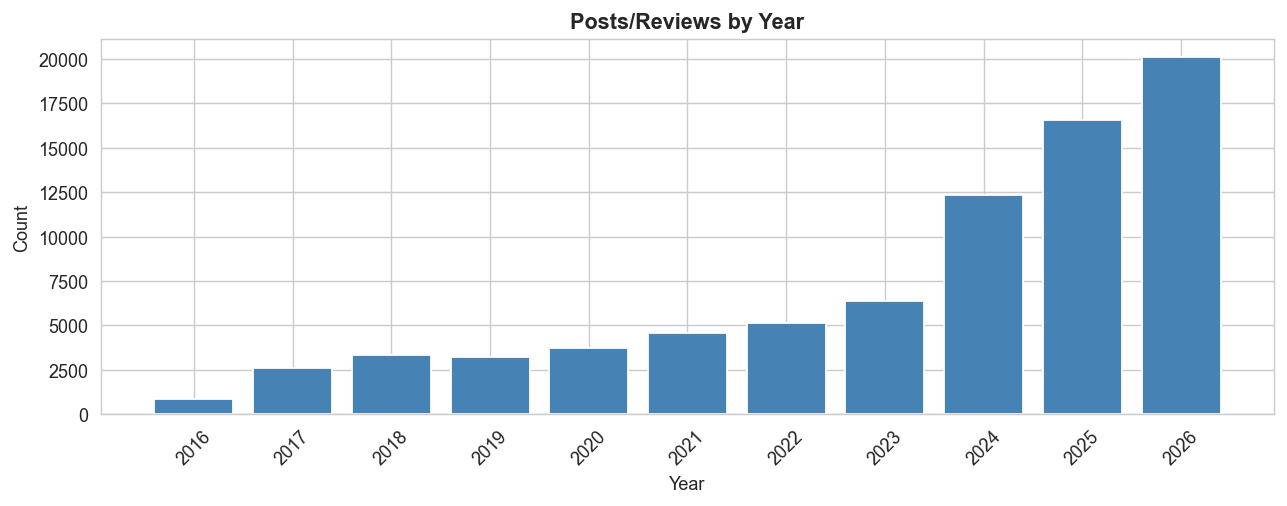

In [5]:
# Chart 1: Posts/Reviews by Year
year_counts = yr.groupby('year').size()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(year_counts.index, year_counts.values, color='steelblue', edgecolor='white')
ax.set_title('Posts/Reviews by Year', fontweight='bold')
ax.set_xlabel('Year'); ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_by_year.png'), dpi=150, bbox_inches='tight')
plt.show()


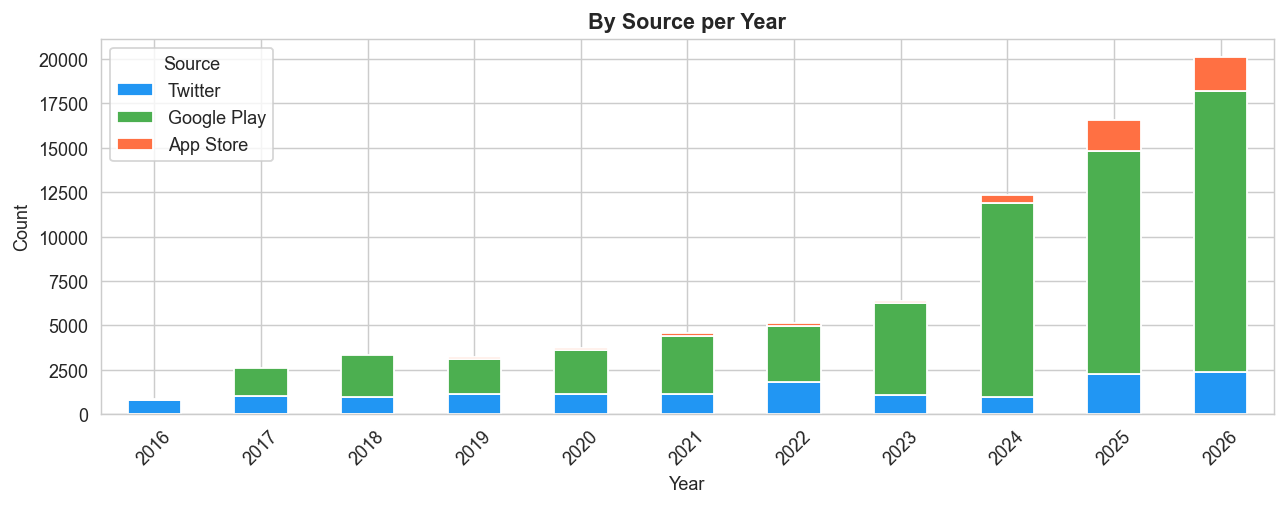

In [6]:
# Chart 2: By Source per Year
pivot = yr.groupby(['year','data_source']).size().unstack(fill_value=0)
col_order = [c for c in ['twitter','google_play','app_store'] if c in pivot.columns]
pivot = pivot[col_order]
color_map = {'twitter':'#2196F3','google_play':'#4CAF50','app_store':'#FF7043'}
colors = [color_map[c] for c in col_order]
labels = {'twitter':'Twitter','google_play':'Google Play','app_store':'App Store'}

pivot.plot(kind='bar', figsize=(10,4), stacked=True, color=colors, edgecolor='white')
plt.title('By Source per Year', fontweight='bold')
plt.xlabel('Year'); plt.ylabel('Count')
plt.tick_params(axis='x', rotation=45)
plt.legend(title='Source', labels=[labels[c] for c in col_order])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_by_source_year.png'), dpi=150, bbox_inches='tight')
plt.show()


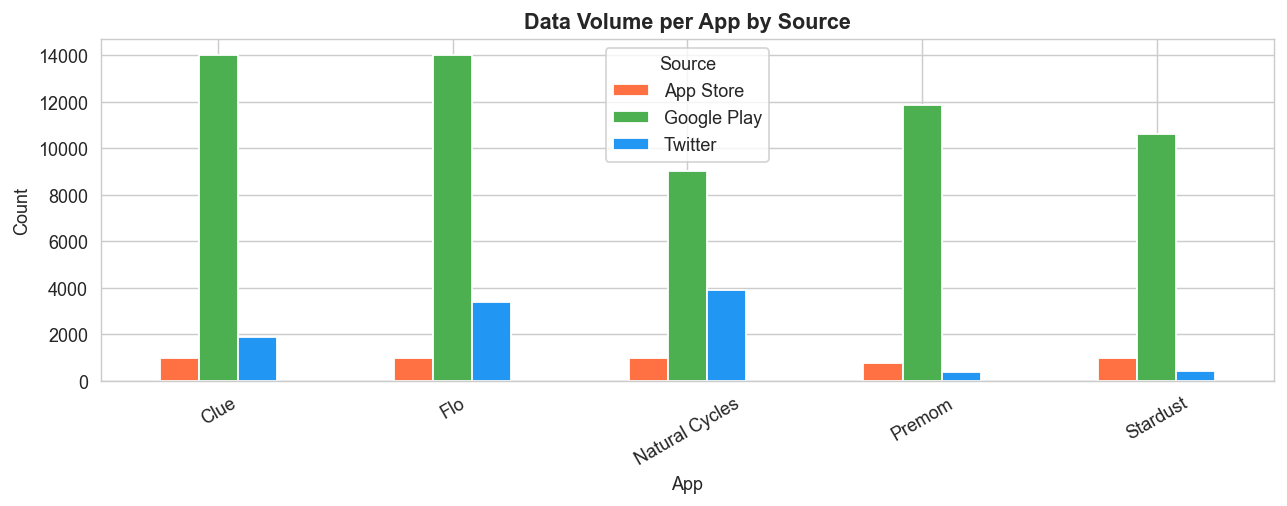

In [7]:
# Chart 3: Data Volume per App
SIX_APPS = ['Flo','Clue','Natural Cycles','Premom','Stardust']
df['app'] = (df['label']
    .str.replace(r'\s+\d{4}.*','',regex=True)
    .str.replace(r'\s+Q[1-4].*','',regex=True)
    .str.replace('NaturalCycles','Natural Cycles')
    .str.strip())

app_df = df[df['app'].isin(SIX_APPS)].groupby(['app','data_source']).size().unstack(fill_value=0)
col_order = [c for c in ['app_store','google_play','twitter'] if c in app_df.columns]
app_df = app_df[col_order]
color_map2 = {'app_store':'#FF7043','google_play':'#4CAF50','twitter':'#2196F3'}
colors2 = [color_map2[c] for c in col_order]

app_df.plot(kind='bar', figsize=(10,4), color=colors2, edgecolor='white')
plt.title('Data Volume per App by Source', fontweight='bold')
plt.xlabel('App'); plt.ylabel('Count')
plt.legend(title='Source', labels=['App Store','Google Play','Twitter'])
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_app_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()


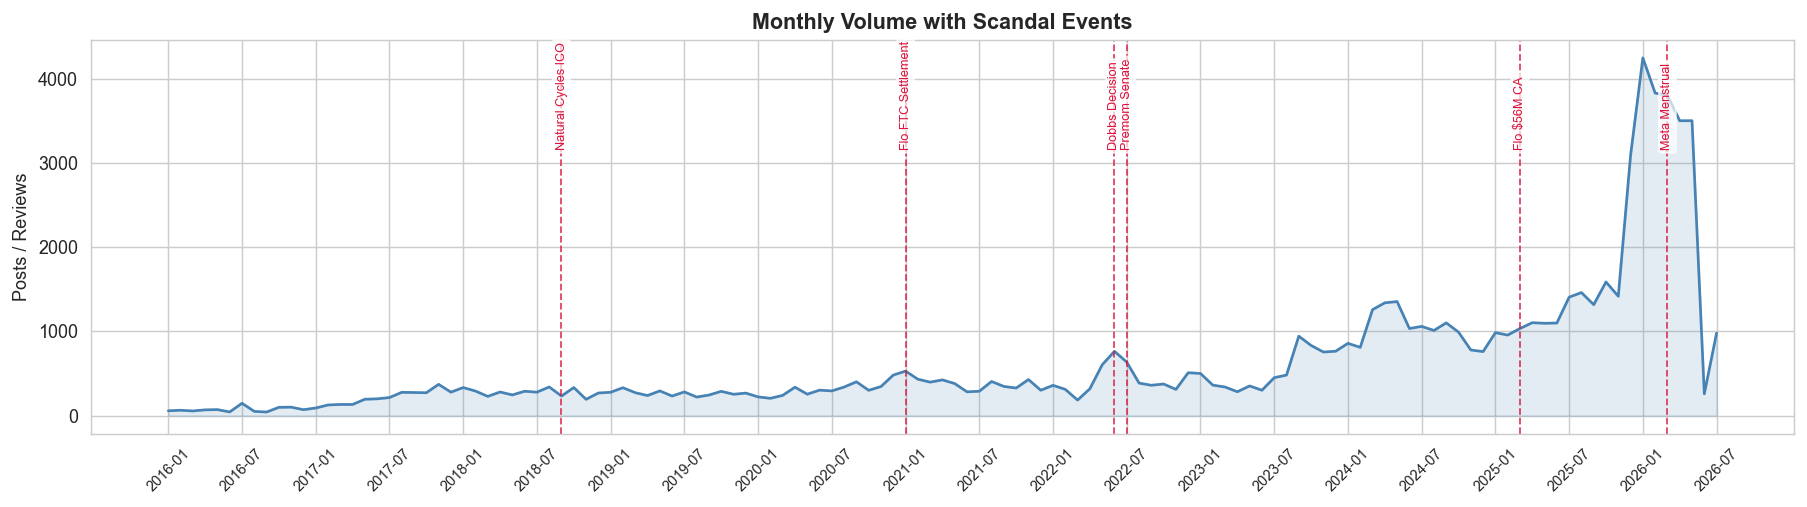

All EDA figures saved to final/


In [8]:
# Chart 4: Monthly Scandal Timeline
SCANDAL_MARKS = [
    ('2018-09','Natural Cycles ICO'),
    ('2021-01','Flo FTC Settlement'),
    ('2022-06','Dobbs Decision'),
    ('2022-07','Premom Senate'),
    ('2025-03','Flo $56M CA'),
    ('2026-03','Meta Menstrual'),
]

monthly = yr[yr['month'].notna()].groupby('month').size()
idx_list = list(monthly.index)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(range(len(monthly)), monthly.values, color='steelblue', linewidth=1.5)
ax.fill_between(range(len(monthly)), monthly.values, alpha=0.15, color='steelblue')

for date_str, label in SCANDAL_MARKS:
    if date_str in idx_list:
        xi = idx_list.index(date_str)
        ax.axvline(xi, color='crimson', linestyle='--', linewidth=1, alpha=0.8)
        ax.text(xi, monthly.max()*0.75, label, fontsize=7, color='crimson',
                ha='center', rotation=90,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

ticks = [i for i,m in enumerate(idx_list) if m.endswith('-01') or m.endswith('-07')]
ax.set_xticks(ticks)
ax.set_xticklabels([idx_list[i] for i in ticks], rotation=45, fontsize=8)
ax.set_title('Monthly Volume with Scandal Events', fontweight='bold')
ax.set_ylabel('Posts / Reviews')
plt.subplots_adjust(top=0.85)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_monthly_scandal_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()
print('All EDA figures saved to final/')


## 4. Preprocess for BERTopic

In [10]:
from langdetect import detect

def preprocess(text):
    text = str(text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'\bRT\b', '', text)
    text = re.sub(r'[^\w\s\'.!?,-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

def is_english(text):
    try: return detect(str(text)) == 'en'
    except: return False

PRIVACY_KW = [
    'privacy', 'data', 'tracking', 'share', 'sharing', 'sell',
    'surveillance', 'trust', 'safe', 'secure', 'leak', 'breach',
    'gdpr', 'hipaa', 'consent', 'delete', 'personal', 'information',
    'third party', 'facebook', 'advertis', 'collect', 'store',
]

mask = df_combined['text'].str.lower().apply(lambda t: any(kw in t for kw in PRIVACY_KW))
df_model = df_combined[mask & (df_combined['text'].str.len() > 80)].copy().reset_index(drop=True)
print(f'After privacy filter: {len(df_model):,}')

print('Filtering English...')
df_model = df_model[df_model['text'].apply(is_english)].reset_index(drop=True)
df_model['text_clean'] = df_model['text'].apply(preprocess)
df_model = df_model[df_model['text_clean'].str.len() > 30].reset_index(drop=True)
texts = df_model['text_clean'].tolist()
print(f'Final BERTopic input: {len(texts):,} texts')


After privacy filter: 16,562
Filtering English...
Final BERTopic input: 16,539 texts


## 5. BERTopic


In [12]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

embedding_model = SentenceTransformer('all-MiniLM-L6-v2')

texts = df_model['text_clean'].tolist()
print(f'Final BERTopic input: {len(texts):,} texts')

umap_model    = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=30, metric='euclidean', prediction_data=True)
vectorizer = CountVectorizer(stop_words='english', min_df=2, ngram_range=(1,2))
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer,
    top_n_words=10,
    verbose=True
)

topics, probs = topic_model.fit_transform(texts)
df_model['topic'] = topics
df_model['topic_prob'] = probs

print(f'Topics found: {len(set(topics))-1}')
topic_model.get_topic_info().head(20)


KeyboardInterrupt: 

In [ ]:
from openai import OpenAI
OPENAI_API_KEY = 'YOUR_API_KEY'
client = OpenAI(api_key=OPENAI_API_KEY)

def label_topic(topic_id, keywords, docs):
    prompt = f"""You are analyzing user discussions about FemTech privacy apps (Flo, Clue, Natural Cycles, Premom, Stardust).

Topic keywords: {', '.join(keywords)}

Sample texts:
{chr(10).join(f'- {d[:150]}' for d in docs[:3])}

Give this topic a SHORT, clear human-readable label (3-5 words max) that describes what users are discussing.
Reply with ONLY the label, nothing else."""

    resp = client.chat.completions.create(
        model='gpt-4o-mini',
        messages=[{'role':'user','content':prompt}],
        max_tokens=20, temperature=0
    )
    return resp.choices[0].message.content.strip()

# Get topic info
topic_info = topic_model.get_topic_info()
topic_info = topic_info[topic_info['Topic'] != -1].reset_index(drop=True)

print('Labeling topics with GPT-4o-mini...\n')
labels = {}
for _, row in topic_info.iterrows():
    tid = row['Topic']
    keywords = [w for w, _ in topic_model.get_topic(tid)]
    rep_docs = topic_model.get_representative_docs(tid)
    label = label_topic(tid, keywords, rep_docs)
    labels[tid] = label
    print(f'  Topic {tid:2d} ({row["Count"]:5,} docs) → {label}')

# Save mapping
df_model['topic_label'] = df_model['topic'].map(labels).fillna('Outlier')

print('\n=== FINAL TOPICS ===')
for tid, label in sorted(labels.items()):
    count = (df_model['topic'] == tid).sum()
    kws = ', '.join([w for w, _ in topic_model.get_topic(tid)][:5])
    print(f'{label:35s} | {count:5,} docs | [{kws}]')

Labeling topics with GPT-4o-mini...

  Topic  0 (1,193 docs) → App login and data issues
  Topic  1 (  892 docs) → FemTech Privacy App Market Trends
  Topic  2 (  879 docs) → Ovulation Tracking Apps
  Topic  3 (  838 docs) → Flo App Privacy Concerns
  Topic  4 (  723 docs) → Natural Climate Cycles Discussion
  Topic  5 (  582 docs) → Clue Plus Advertising Frustration
  Topic  6 (  416 docs) → App Annoyances and Ads
  Topic  7 (  376 docs) → FemTech App User Experiences
  Topic  8 (  333 docs) → User Love for Tracking Apps
  Topic  9 (  311 docs) → FemTech Privacy Concerns
  Topic 10 (  309 docs) → FemTech Privacy Concerns
  Topic 11 (  262 docs) → User Experience with FemTech Apps
  Topic 12 (  219 docs) → Natural Birth Control Apps
  Topic 13 (  210 docs) → Astrology and Period Tracking
  Topic 14 (  206 docs) → FemTech App Privacy Concerns
  Topic 15 (  199 docs) → FemTech Privacy and Surveillance
  Topic 16 (  196 docs) → Ads and Premium Upselling
  Topic 17 (  194 docs) → GPS Locat

2026-07-22 10:21:36,237 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


Saved: femtech_with_topics.csv + bertopic_model_final


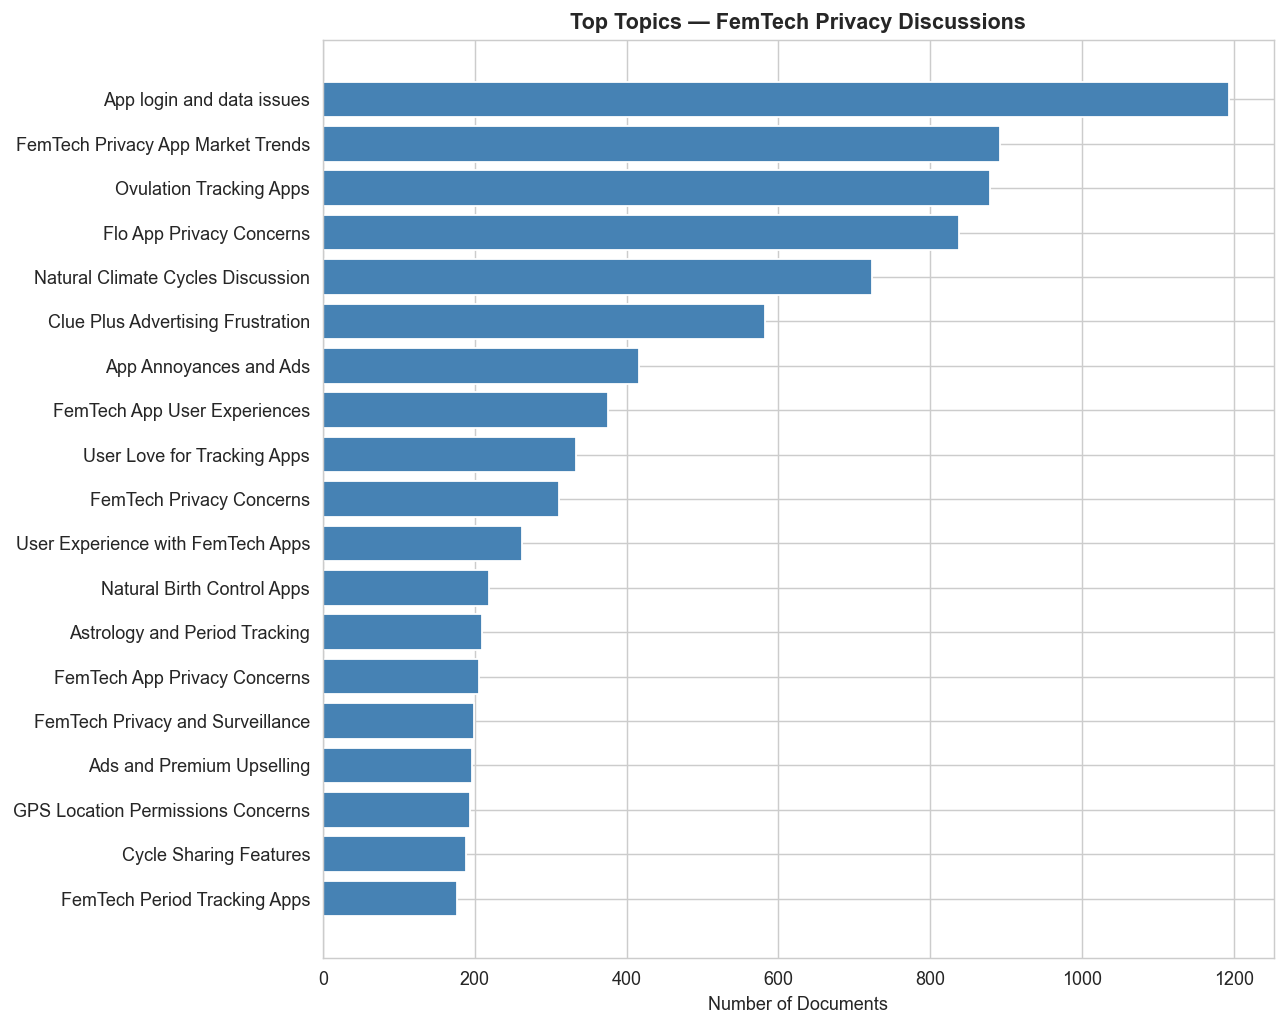

In [ ]:
# Save model and results
df_model.to_csv(os.path.join(OUT_DIR, 'femtech_with_topics.csv'), index=False)
topic_model.save(os.path.join(OUT_DIR, 'bertopic_model_final'))
print('Saved: femtech_with_topics.csv + bertopic_model_final')

# Top topics bar chart with GPT labels
topic_info = topic_model.get_topic_info()
topic_info = topic_info[topic_info['Topic'] != -1].copy()
topic_info['label'] = topic_info['Topic'].map(labels).fillna('Other')
topic_info = topic_info.sort_values('Count', ascending=True).tail(20)

plt.figure(figsize=(10, 8))
plt.barh(topic_info['label'], topic_info['Count'], color='steelblue', edgecolor='white')
plt.title('Top Topics — FemTech Privacy Discussions', fontweight='bold')
plt.xlabel('Number of Documents')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_topics.png'), dpi=150, bbox_inches='tight')
plt.show()


## 6. Sentiment Analysis (RoBERTa)

In [ ]:
# ── Section 6: LLM-based Sentiment Analysis (GPT-4o-mini) ──────────────
from openai import OpenAI
from concurrent.futures import ThreadPoolExecutor, as_completed

client = OpenAI(api_key=OPENAI_API_KEY)

SENTIMENT_PROMPT = """Classify the sentiment of this user review or social media post about a FemTech app (period tracker, fertility app, etc.).

Respond with ONLY one word: positive, negative, or neutral

Text: {text}"""

def get_sentiment_llm(text):
    try:
        resp = client.chat.completions.create(
            model='gpt-4o-mini',
            messages=[{'role': 'user', 'content': SENTIMENT_PROMPT.format(text=str(text)[:600])}],
            max_tokens=5,
            temperature=0
        )
        label = resp.choices[0].message.content.strip().lower()
        return label if label in ('positive', 'negative', 'neutral') else 'neutral'
    except:
        return 'neutral'

print('LLM sentiment (GPT-4o-mini) ready.')

LLM sentiment (GPT-4o-mini) ready.


In [1]:
import asyncio, time
import nest_asyncio
nest_asyncio.apply()
from openai import AsyncOpenAI, RateLimitError
from collections import Counter

async_client = AsyncOpenAI(api_key=OPENAI_API_KEY)

df_test = df_combined[df_combined['text'].str.len() > 20].copy().reset_index(drop=True)
test_texts = list(enumerate(df_test['text'].tolist()[:100]))

PROMPT = """Classify the sentiment of this FemTech app review or social media post. Skip if it is not in English.

Rules:
- Use "positive" if there is ANY positive emotion (love, like, great, helpful, recommend, etc.)
- Use "negative" if there is ANY negative emotion (hate, bad, scary, concerned, deleted, disappointed, etc.)  
- Use "neutral" ONLY if the text is purely factual with zero emotional content
- When in doubt, pick positive or negative — avoid neutral

Text: {text}

Reply with exactly one word: positive, negative, or neutral"""

async def get_one(sem, idx, text):
    async with sem:
        for attempt in range(4):
            try:
                r = await async_client.chat.completions.create(
                    model='gpt-4o-mini',
                    messages=[{'role':'user','content': PROMPT.format(text=str(text)[:600])}],
                    max_tokens=10, temperature=0
                )
                raw = r.choices[0].message.content.strip().lower()
                for word in ('positive', 'negative', 'neutral'):
                    if word in raw:
                        return idx, word
                return idx, 'positive'
            except RateLimitError:
                await asyncio.sleep(5 * (2 ** attempt))
            except Exception as e:
                await asyncio.sleep(2)
        return idx, 'neutral'

async def test_run():
    sem = asyncio.Semaphore(15)
    tasks = [get_one(sem, i, t) for i, t in test_texts]
    results = await asyncio.gather(*tasks)
    return dict(results)

test_results = asyncio.run(test_run())

# Показываем результаты
dist = Counter(test_results.values())
print(f'Distribution: {dict(dist)}')
print(f'positive: {dist["positive"]}%  negative: {dist["negative"]}%  neutral: {dist["neutral"]}%')
print()

# Показываем 10 примеров с их лейблами
for i in range(10):
    text_preview = df_test['text'].iloc[i][:100].replace('\n', ' ')
    print(f'[{test_results[i]:8s}] {text_preview}')

NameError: name 'OPENAI_API_KEY' is not defined

In [ ]:
import os, json, time
from openai import OpenAI
from collections import Counter

client = OpenAI(api_key=OPENAI_API_KEY)
WORKDIR = os.path.join(OUT_DIR, 'batch_sentiment')
TRACK   = os.path.join(WORKDIR, 'tracking.json')
RESULTS = os.path.join(WORKDIR, 'results.csv')

PROMPT = """Classify sentiment of this FemTech app review.
- skip: not in English
- positive: ANY positive feeling
- negative: ANY negative feeling
- neutral: ONLY if purely factual, zero emotion
If unsure between neutral and positive/negative, pick positive or negative.
Reply one word: positive, negative, neutral, or skip.

Text: {text}"""

df_sent = df_combined[df_combined['text'].str.len() > 20].copy().reset_index(drop=True)
texts = df_sent['text'].tolist()
N = len(texts)
def est_tokens(t): return len(str(t)[:400]) // 4 + 40

results = {}
if os.path.exists(RESULTS):
    r = pd.read_csv(RESULTS, dtype={'idx': int}); results = dict(zip(r['idx'], r['label']))
print(f'Already have {len(results):,}/{N:,}')
tracking = json.load(open(TRACK))

def save_track():   json.dump(tracking, open(TRACK,'w'))
def save_results(): pd.DataFrame({'idx':list(results.keys()),'label':list(results.values())}).to_csv(RESULTS, index=False)

# Сброс зависших батчей в pending при старте
for c in tracking['chunks']:
    if c['batch_id'] and not c['collected']:
        try:
            b = client.batches.retrieve(c['batch_id'])
            if b.status in ('failed','expired','cancelled'):
                c['batch_id']=None; c['status']='pending'
        except: pass
save_track()

HARD_LIMIT = 1_200_000  # запас под лимит очереди 2M

def chunk_tokens(c):
    a,b = c['ids']; return sum(est_tokens(texts[i]) for i in range(a,b+1) if i not in results)

def enqueued():
    tot = 0
    for c in tracking['chunks']:
        if c['batch_id'] and not c['collected'] and c['status'] in ('validating','in_progress','finalizing'):
            tot += chunk_tokens(c)
    return tot

def submit(c):
    a,b = c['ids']
    lines = [json.dumps({"custom_id":str(i),"method":"POST","url":"/v1/chat/completions",
             "body":{"model":"gpt-4o-mini","messages":[{"role":"user","content":PROMPT.format(text=str(texts[i])[:400])}],
                     "max_tokens":2,"temperature":0}}) for i in range(a,b+1) if i not in results]
    if not lines: c['collected']=True; save_track(); return
    p = os.path.join(WORKDIR, f'req_{a}_{b}.jsonl'); open(p,'w').write('\n'.join(lines))
    f = client.files.create(file=open(p,'rb'), purpose='batch')
    batch = client.batches.create(input_file_id=f.id, endpoint='/v1/chat/completions', completion_window='24h')
    c['batch_id']=batch.id; c['status']=batch.status; save_track()
    print(f'  submitted {a}-{b} -> {batch.id}')

def collect(c):
    batch = client.batches.retrieve(c['batch_id']); c['status']=batch.status
    if batch.status=='completed' and batch.output_file_id:
        for line in client.files.content(batch.output_file_id).text.splitlines():
            if not line.strip(): continue
            o=json.loads(line); cid=int(o['custom_id'])
            try:
                raw=o['response']['body']['choices'][0]['message']['content'].strip().lower()
                results[cid]=next((w for w in ('skip','positive','negative','neutral') if w in raw),'positive')
            except: results[cid]='error'
        c['collected']=True; save_results(); save_track()
        print(f'  collected {c["ids"]} ({len(results):,}/{N:,})')
    elif batch.status in ('failed','expired','cancelled'):
        print(f'  {c["ids"]} {batch.status}: {getattr(batch,"errors",None)}')
        c['batch_id']=None; c['status']='pending'; save_track()

while True:
    for c in tracking['chunks']:
        if c['batch_id'] and not c['collected']: collect(c)
    for c in tracking['chunks']:
        if not c['collected'] and not c['batch_id']:
            if enqueued() + chunk_tokens(c) <= HARD_LIMIT: submit(c)
    left=[c for c in tracking['chunks'] if not c['collected']]
    d=Counter(results.values())
    print(f'{len(results):,}/{N:,} | left {len(left)} | pos={d["positive"]} neg={d["negative"]} neu={d["neutral"]} skip={d.get("skip",0)} | enq~{enqueued():,}tok')
    if not left: break
    time.sleep(60)

df_sent['sentiment_gpt']=[results.get(i,'error') for i in range(N)]
df_sent.to_csv(os.path.join(OUT_DIR,'femtech_sentiment_gpt.csv'),index=False)
print('\nDONE'); print(df_sent['sentiment_gpt'].value_counts().to_string())

Already have 30,322/65,322
  collected [30000, 34999] (35,322/65,322)
  submitted 35000-39999 -> batch_6a6707ef60708190abe4e2fd97702045
  submitted 40000-44999 -> batch_6a6707f17fbc8190ac0de25954ed56c5
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
35,322/65,322 | left 6 | pos=19385 neg=14886 neu=628 skip=423 | enq~854,798tok
  collected [35000, 39999] (40,322/65,322)
  submitted 45000-49999 -> batch_6a6709da875881908ae69b9e96bf4ae6
40,322/65,322 | left 5 | pos=22390 neg=16830 neu=663 skip

In [ ]:
caffeinate -i

In [ ]:
from transformers import pipeline
import torch

device = 'mps' if torch.backends.mps.is_available() else (-1)

sentiment_pipe = pipeline(
    'sentiment-analysis',
    model='cardiffnlp/twitter-roberta-base-sentiment-latest',
    device=device,
    truncation=True,
    max_length=512
)

df_sent = df_combined[df_combined['text'].str.len() > 20].copy().reset_index(drop=True)
texts = df_sent['text'].tolist()

BATCH = 256
all_results = []
for i in range(0, len(texts), BATCH):
    out = sentiment_pipe(texts[i:i+BATCH], batch_size=BATCH)
    all_results.extend(out)
    if i % 10000 == 0:
        print(f'  {i:,}/{len(texts):,}')

df_sent['sentiment_roberta'] = [r['label'].lower() for r in all_results]
df_sent['sentiment_roberta_score'] = [r['score'] for r in all_results]

df_sent.to_csv(os.path.join(OUT_DIR, 'femtech_sentiment_roberta.csv'), index=False)

df_sent['sentiment_label'] = df_sent['sentiment_roberta']
df_sent.to_csv(os.path.join(OUT_DIR, 'femtech_with_sentiment.csv'), index=False)

print('Done!')
print(df_sent['sentiment_roberta'].value_counts().to_string())

Device: mps


Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use mps


  0/65,322
Done!
sentiment_roberta
positive    30819
negative    22603
neutral     11900


## 7. Visualizations

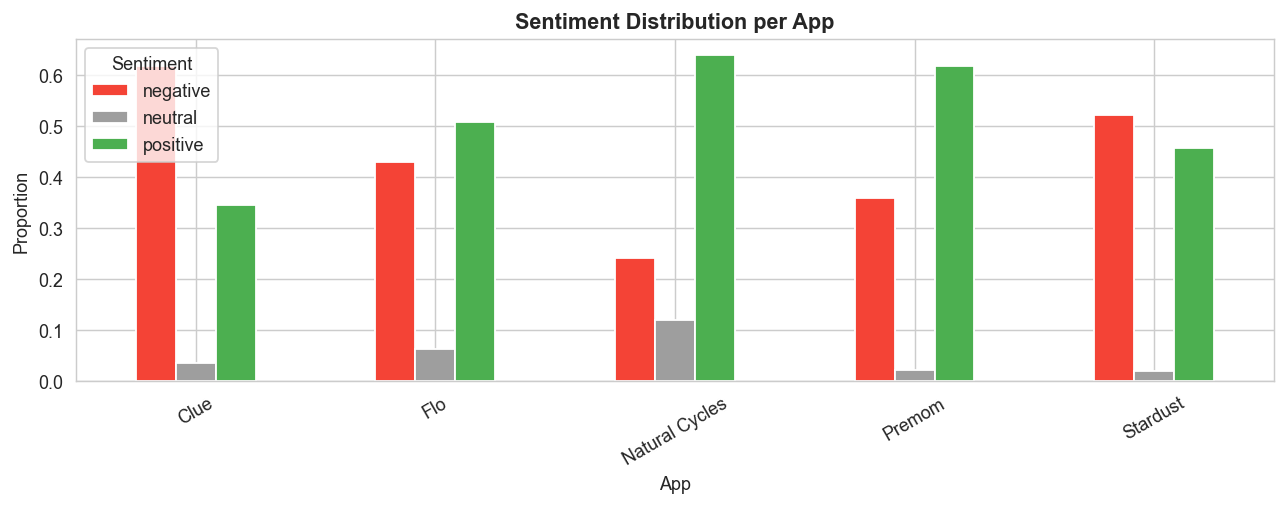

In [ ]:
# ===== Section 7: Visualizations =====
df_sent = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_gpt.csv'), low_memory=False)
SENT = 'sentiment_gpt'   # основной метод (GPT-4o-mini)

df_sent['app'] = (df_sent['label'].astype(str)
    .str.replace(r'\s+\d{4}.*','',regex=True)
    .str.replace(r'\s+Q[1-4].*','',regex=True)
    .str.replace('NaturalCycles','Natural Cycles')
    .str.strip())

APPS = ['Flo','Clue','Natural Cycles','Premom','Stardust']
d = df_sent[df_sent['app'].isin(APPS) & df_sent[SENT].isin(['positive','negative','neutral'])]
sent_pivot = d.groupby(['app', SENT]).size().unstack(fill_value=0)
sent_pct = sent_pivot.div(sent_pivot.sum(axis=1), axis=0)

col_order = [c for c in ['negative','neutral','positive'] if c in sent_pct.columns]
sent_pct[col_order].plot(kind='bar', figsize=(10,4),
    color=['#F44336','#9E9E9E','#4CAF50'], edgecolor='white')
plt.title('Sentiment Distribution per App', fontweight='bold')
plt.xlabel('App'); plt.ylabel('Proportion')
plt.xticks(rotation=30); plt.legend(title='Sentiment')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_sentiment_by_app.png'), dpi=150, bbox_inches='tight')
plt.show()

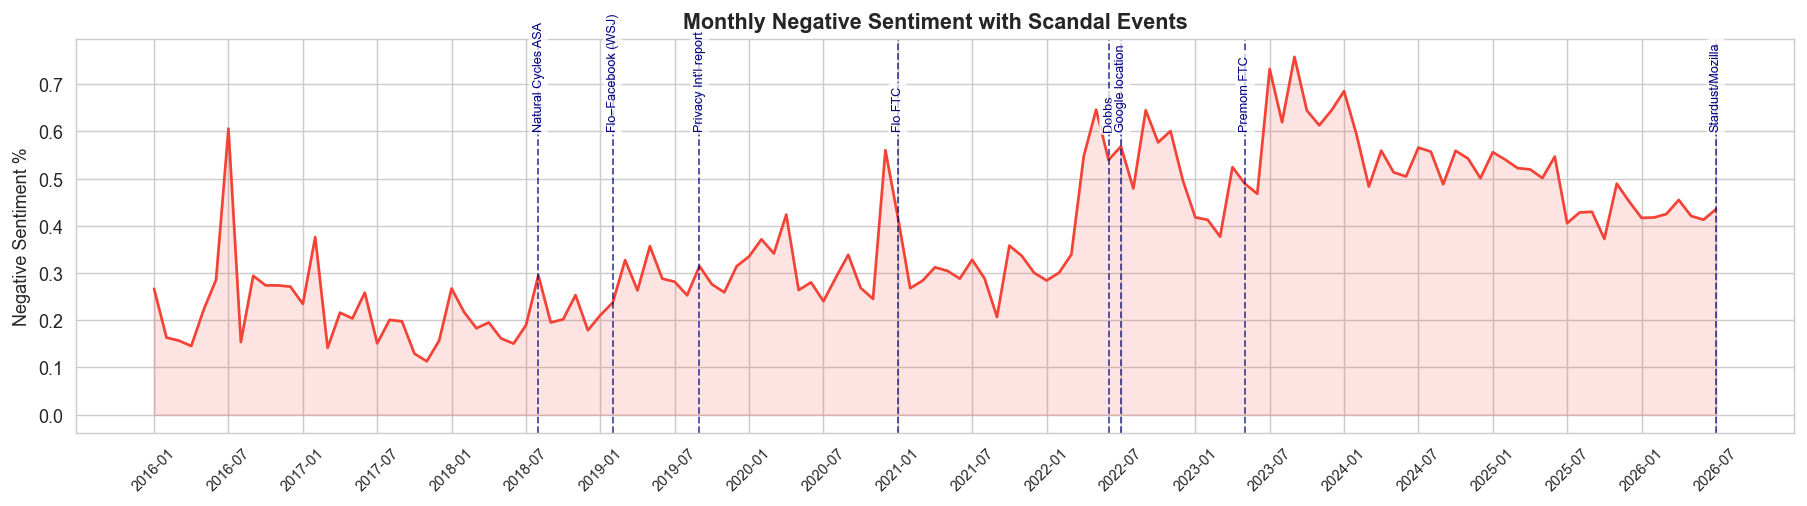

In [ ]:
SCANDAL_MARKS = [
    ('2018-08','Natural Cycles ASA'),
    ('2019-02','Flo–Facebook (WSJ)'),
    ('2019-09',"Privacy Int'l report"),
    ('2021-01','Flo FTC'),
    ('2022-06','Dobbs'),
    ('2022-07','Google location'),
    ('2023-05','Premom FTC'),
    ('2026-07','Stardust/Mozilla'),
]


# Sentiment over time
SENT = 'sentiment_gpt'

df_sent = df_sent[df_sent[SENT].isin(['positive','negative','neutral'])].copy()
df_sent['month'] = pd.to_datetime(df_sent['date'], errors='coerce').dt.to_period('M').astype(str)
monthly = df_sent[df_sent['month'].notna() & (df_sent['month'] >= '2016-01')]\
    .groupby(['month', SENT]).size().unstack(fill_value=0)

if 'negative' in monthly.columns:
    neg_pct = monthly['negative'] / monthly.sum(axis=1)
    idx = list(neg_pct.index)
    fig, ax = plt.subplots(figsize=(14,4))
    ax.plot(range(len(idx)), neg_pct.values, color='#F44336', linewidth=1.5)
    ax.fill_between(range(len(idx)), neg_pct.values, alpha=0.15, color='#F44336')
    for ds, lbl in SCANDAL_MARKS:
        if ds in idx:
            xi = idx.index(ds)
            ax.axvline(xi, color='navy', linestyle='--', linewidth=1, alpha=0.7)
            ax.text(xi, neg_pct.max()*0.8, lbl, fontsize=7, color='navy',
                    ha='center', rotation=90, bbox=dict(boxstyle='round,pad=0.2',fc='white',alpha=0.7))
    ticks = [i for i,m in enumerate(idx) if m.endswith('-01') or m.endswith('-07')]
    ax.set_xticks(ticks); ax.set_xticklabels([idx[i] for i in ticks], rotation=45, fontsize=8)
    ax.set_title('Monthly Negative Sentiment with Scandal Events', fontweight='bold')
    ax.set_ylabel('Negative Sentiment %')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, 'fig_sentiment_timeline.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 8. Say-Do Gap Advanced Analysis

In [ ]:
# ===== Advanced Analysis SETUP =====
import json, numpy as np
from math import pi
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 140

POLICY_FILE = os.path.join(THESIS, 'raw_data', 'policy_scores.json')
ADV = os.path.join(OUT_DIR, 'adv'); os.makedirs(ADV, exist_ok=True)

df_gpt = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_gpt.csv'), low_memory=False)
df_top = pd.read_csv(os.path.join(OUT_DIR, 'femtech_with_topics.csv'), low_memory=False)

def clean_app(s):
    return (s.astype(str).str.replace(r'\s+\d{4}.*','',regex=True)
            .str.replace(r'\s+Q[1-4].*','',regex=True)
            .str.replace('NaturalCycles','Natural Cycles').str.strip())

APPS = ['Flo','Clue','Natural Cycles','Premom','Stardust']
DIMS = ['data_collection_clarity','third_party_disclosure','user_control',
        'data_retention','legal_basis','plain_language']
DIM_LBL = ['Data collection','Third-party disc.','User control','Data retention','Legal basis','Plain language']
print('Advanced analysis setup ready')

Advanced analysis setup ready


           App  SAY   DO   Gap
           Flo 50.0 38.4  11.6
          Clue 55.0 30.1  24.9
Natural Cycles 48.3 64.8 -16.4
        Premom 46.7 49.4  -2.7
      Stardust 48.3 44.6   3.7


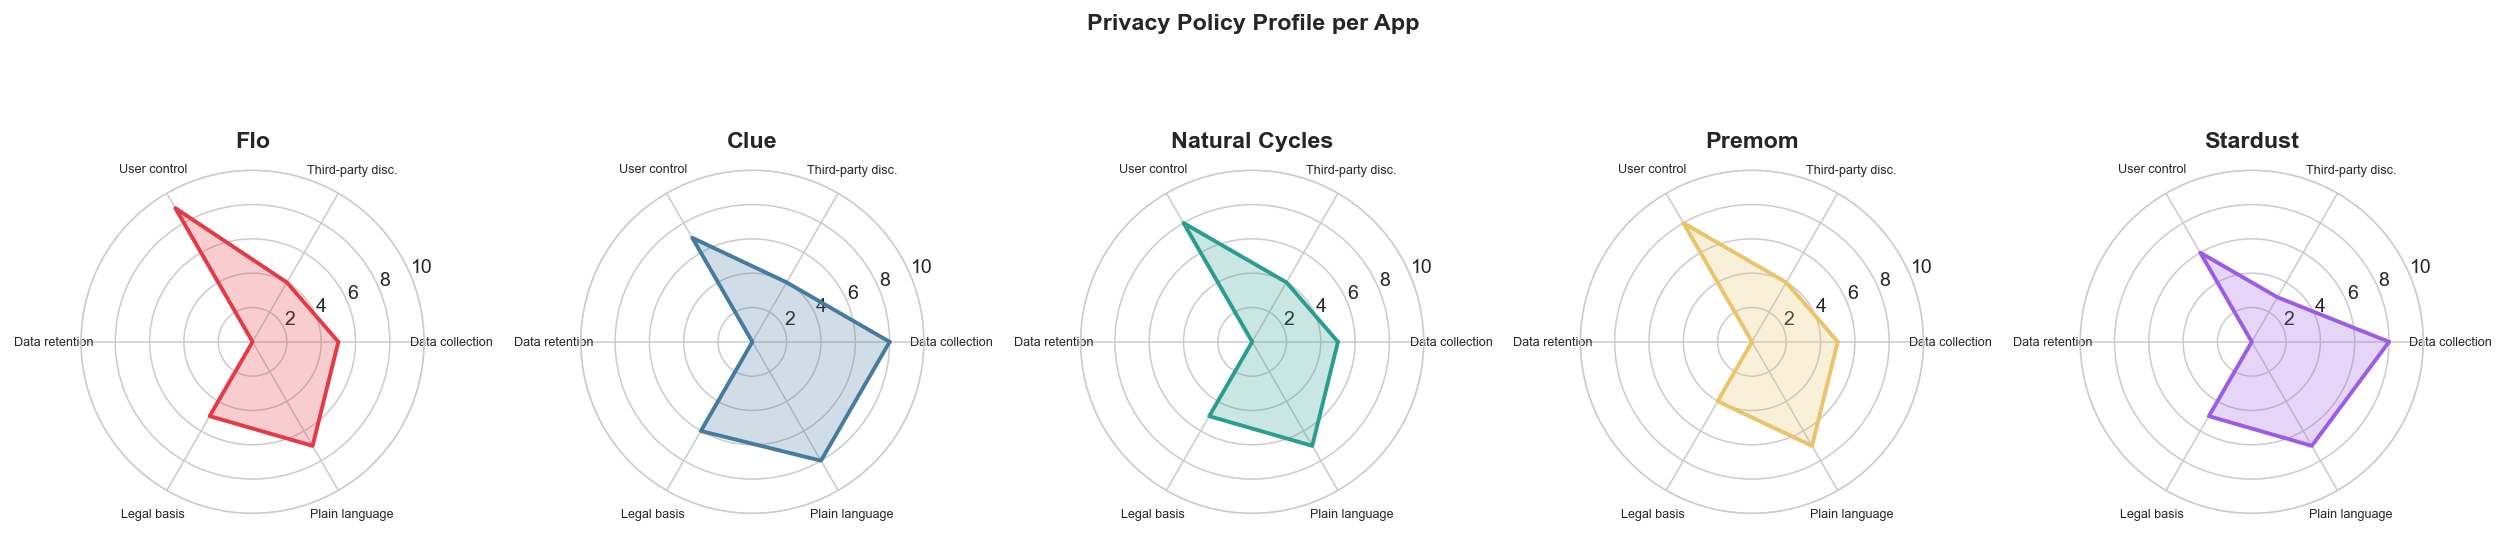

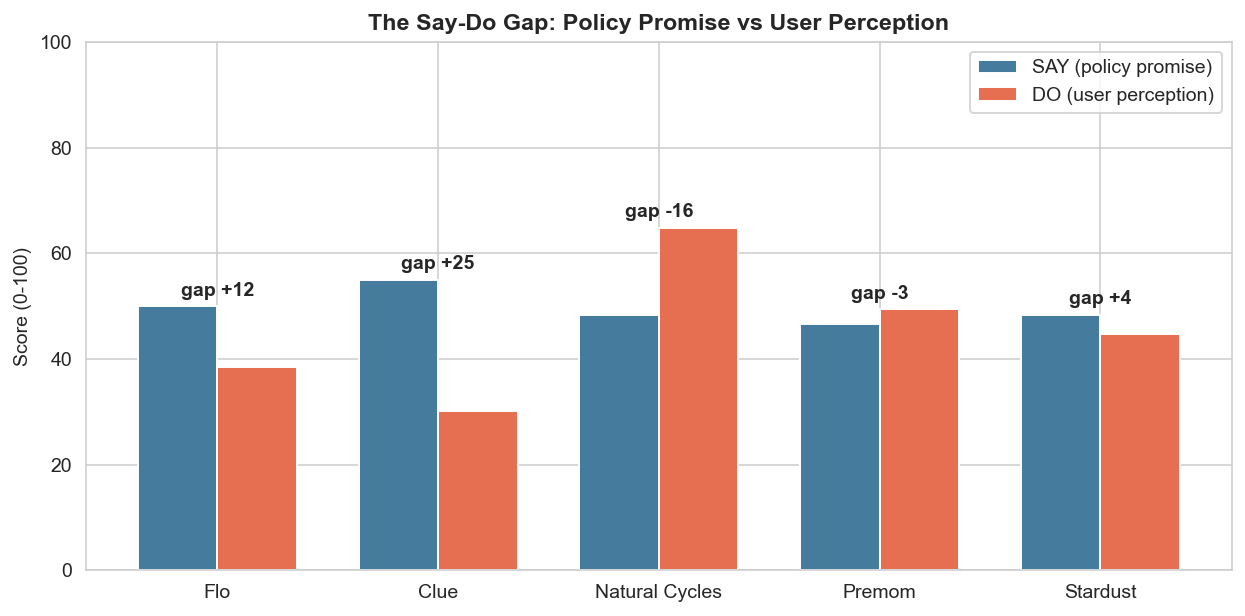

In [ ]:
# 8.A — Say-Do Gap + policy visuals
ps = json.load(open(POLICY_FILE))
keymap = {'Natural Cycles':'NaturalCycles'}
mat = np.array([[ps[keymap.get(a,a)][d]['score'] for d in DIMS] for a in APPS], float)  # 5x6
say = mat.mean(axis=1) * 10  # 0-100

# DO = perceived trust: % positive among pos+neg on privacy-relevant docs per app
df_gpt['app'] = clean_app(df_gpt['label'])
PRIV = ['privacy','data','tracking','share','sell','surveillance','trust','leak',
        'breach','consent','third party','facebook','collect']
df_gpt['priv'] = df_gpt['text'].astype(str).str.lower().apply(lambda t: any(k in t for k in PRIV))
gp = df_gpt[df_gpt['priv'] & df_gpt['app'].isin(APPS) & df_gpt['sentiment_gpt'].isin(['positive','negative'])]
do = np.array([100*(gp[gp['app']==a]['sentiment_gpt']=='positive').mean() for a in APPS])
gap = say - do

saydo = pd.DataFrame({'App':APPS,'SAY':say.round(1),'DO':do.round(1),'Gap':gap.round(1)})
saydo.to_csv(os.path.join(ADV,'say_do_gap.csv'), index=False)
print(saydo.to_string(index=False))

# heatmap
fig,ax=plt.subplots(figsize=(8,4.2))
im=ax.imshow(mat,cmap='RdYlGn',vmin=0,vmax=10,aspect='auto')
ax.set_xticks(range(6)); ax.set_xticklabels(DIM_LBL,fontsize=8,rotation=20)
ax.set_yticks(range(5)); ax.set_yticklabels(APPS)
for i in range(5):
    for j in range(6): ax.text(j,i,int(mat[i,j]),ha='center',va='center',fontweight='bold')
plt.colorbar(im,label='Score (0-10)'); ax.set_title('Privacy Policy Scores by Dimension',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_policy_heatmap.png'),bbox_inches='tight'); plt.show()

# radar
ang=[n/6*2*pi for n in range(6)]; ang+=ang[:1]
fig,axes=plt.subplots(1,5,figsize=(18,4),subplot_kw=dict(polar=True))
cols=['#E63946','#457B9D','#2A9D8F','#E9C46A','#9B5DE5']
for k,a in enumerate(APPS):
    v=list(mat[k])+[mat[k][0]]
    axes[k].plot(ang,v,color=cols[k],lw=2); axes[k].fill(ang,v,color=cols[k],alpha=0.25)
    axes[k].set_xticks(ang[:-1]); axes[k].set_xticklabels(DIM_LBL,fontsize=6.5)
    axes[k].set_ylim(0,10); axes[k].set_title(a,fontweight='bold',pad=12)
plt.suptitle('Privacy Policy Profile per App',fontweight='bold',y=1.05)
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_policy_radar.png'),bbox_inches='tight'); plt.show()

# say-do gap bars
fig,ax=plt.subplots(figsize=(9,4.5)); x=np.arange(5); w=0.36
ax.bar(x-w/2,say,w,label='SAY (policy promise)',color='#457B9D')
ax.bar(x+w/2,do,w,label='DO (user perception)',color='#E76F51')
for i in range(5): ax.annotate(f'gap {gap[i]:+.0f}',(i,max(say[i],do[i])+2),ha='center',fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(APPS); ax.set_ylim(0,100); ax.set_ylabel('Score (0-100)')
ax.set_title('The Say-Do Gap: Policy Promise vs User Perception',fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_say_do_gap.png'),bbox_inches='tight'); plt.show()

AHP weights: {'Data collection': np.float64(0.184), 'Third-party disc.': np.float64(0.339), 'User control': np.float64(0.233), 'Data retention': np.float64(0.12), 'Legal basis': np.float64(0.074), 'Plain language': np.float64(0.049)} | CR=0.020
           App  TOPSIS  Rank
          Clue   0.683     1
           Flo   0.592     2
Natural Cycles   0.538     3
        Premom   0.526     4
      Stardust   0.407     5


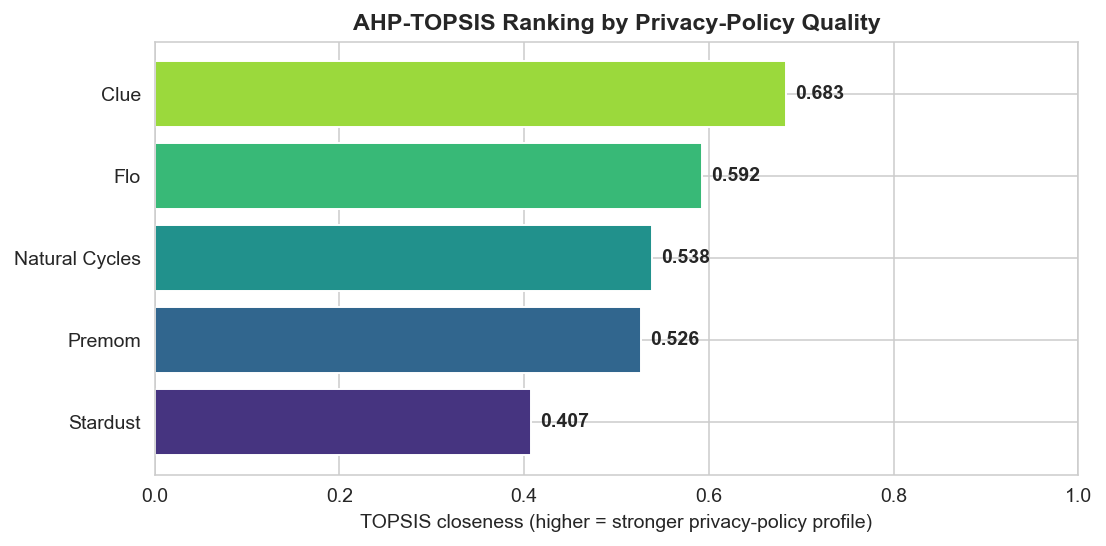

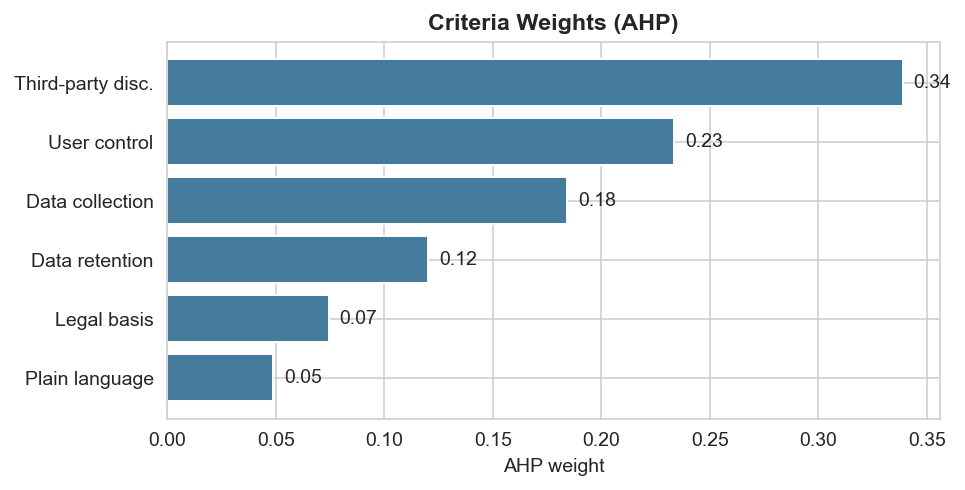

In [ ]:
# 8.B — AHP-TOPSIS ranking (Alhoshan method):
ps = json.load(open(POLICY_FILE)); keymap={'Natural Cycles':'NaturalCycles'}
X = np.array([[ps[keymap.get(a,a)][d]['score'] for d in DIMS] for a in APPS], float)  # 5 apps x 6 crit

# --- AHP: pairwise comparison of criteria (Saaty scale) ---
P = np.array([
 [1,   1/2, 1/2, 2,   3,   4  ],
 [2,   1,   2,   3,   4,   5  ],
 [2,   1/2, 1,   2,   3,   4  ],
 [1/2, 1/3, 1/2, 1,   2,   3  ],
 [1/3, 1/4, 1/3, 1/2, 1,   2  ],
 [1/4, 1/5, 1/4, 1/3, 1/2, 1  ],
], float)
ev,evec = np.linalg.eig(P); k=np.argmax(ev.real)
w = np.abs(evec[:,k].real); w=w/w.sum()
CR = ((ev.real[k]-6)/5) / 1.24
print('AHP weights:', dict(zip(DIM_LBL, w.round(3))), f'| CR={CR:.3f}')

# --- TOPSIS ---
norm = np.sqrt((X**2).sum(axis=0)); norm[norm==0]=1
V = (X/norm) * w
best, worst = V.max(0), V.min(0)
Dp = np.sqrt(((V-best)**2).sum(1)); Dm = np.sqrt(((V-worst)**2).sum(1))
C = Dm/(Dp+Dm)
topsis = pd.DataFrame({'App':APPS,'TOPSIS':C.round(3)}).sort_values('TOPSIS',ascending=False)
topsis['Rank']=range(1,6); topsis.to_csv(os.path.join(ADV,'topsis_ranking.csv'),index=False)
print(topsis.to_string(index=False))

r = topsis.sort_values('TOPSIS')
fig,ax=plt.subplots(figsize=(8,4))
bars=ax.barh(r['App'],r['TOPSIS'],color=plt.cm.viridis(np.linspace(0.15,0.85,5)))
for b,v in zip(bars,r['TOPSIS']): ax.text(v+0.01,b.get_y()+b.get_height()/2,f'{v:.3f}',va='center',fontweight='bold')
ax.set_xlim(0,1); ax.set_xlabel('TOPSIS closeness (higher = stronger privacy-policy profile)')
ax.set_title('AHP-TOPSIS Ranking by Privacy-Policy Quality',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_topsis_ranking.png'),bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(7,3.6)); o=np.argsort(w)
ax.barh(np.array(DIM_LBL)[o],w[o],color='#457B9D')
for i,wi in enumerate(w[o]): ax.text(wi+0.005,i,f'{wi:.2f}',va='center')
ax.set_xlabel('AHP weight'); ax.set_title('Criteria Weights (AHP)',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_ahp_weights.png'),bbox_inches='tight'); plt.show()

               Event  Neg% before  Neg% after   Δpp
  Natural Cycles ASA         16.9        23.6   6.7
  Flo–Facebook (WSJ)         19.5        27.3   7.9
Privacy Int'l report         27.0        28.3   1.3
             Flo FTC         44.0        33.6 -10.4
               Dobbs         61.2        53.8  -7.4
          Premom FTC         44.3        57.8  13.5


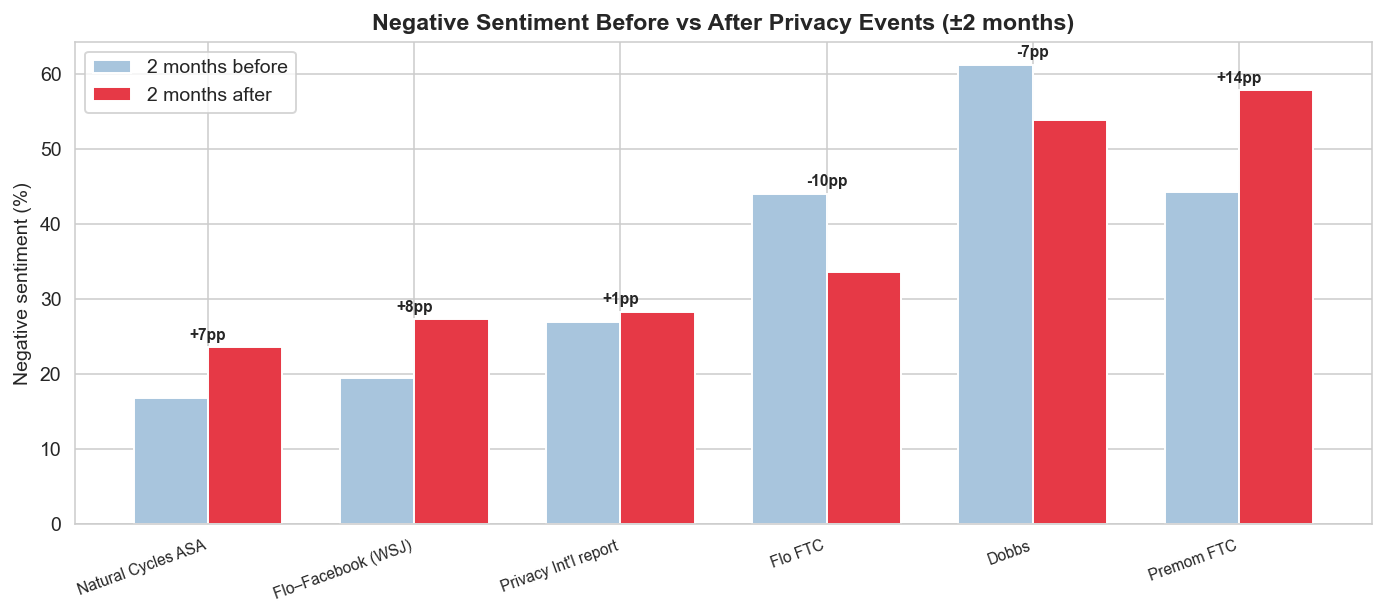

In [ ]:
# 8.C — Event study (reaction to scandals ±2 months):

df_gpt['dt'] = pd.to_datetime(df_gpt['date'], errors='coerce')
gg = df_gpt[df_gpt['sentiment_gpt'].isin(['positive','negative','neutral'])].dropna(subset=['dt']).copy()
gg['ym'] = gg['dt'].dt.to_period('M')

# Все проверенные события — для маркеров на тренде
EVENTS_MARK = [
    ('2018-08','Natural Cycles ASA'), ('2019-02','Flo–Facebook (WSJ)'),
    ('2019-09',"Privacy Int'l report"), ('2021-01','Flo FTC'),
    ('2022-06','Dobbs'), ('2022-07','Google location'),
    ('2023-05','Premom FTC'), ('2026-07','Stardust/Mozilla'),
]
# Подмножество с чистыми окнами ±2мес — для before/after анализа
EVENTS_STUDY = [
    ('2018-08','Natural Cycles ASA'), ('2019-02','Flo–Facebook (WSJ)'),
    ('2019-09',"Privacy Int'l report"), ('2021-01','Flo FTC'),
    ('2022-06','Dobbs'), ('2023-05','Premom FTC'),
]
negshare = lambda s: 100*(s['sentiment_gpt']=='negative').mean() if len(s) else np.nan

rows=[]
for ev,lbl in EVENTS_STUDY:
    e=pd.Period(ev,'M')
    before=gg[(gg['ym']>=e-2)&(gg['ym']<=e-1)]; after=gg[(gg['ym']>=e)&(gg['ym']<=e+2)]
    rows.append({'Event':lbl,'Neg% before':round(negshare(before),1),
                 'Neg% after':round(negshare(after),1),'Δpp':round(negshare(after)-negshare(before),1)})
ev_tab=pd.DataFrame(rows); ev_tab.to_csv(os.path.join(ADV,'event_study.csv'),index=False)
print(ev_tab.to_string(index=False))

fig,ax=plt.subplots(figsize=(10,4.5)); x=np.arange(len(EVENTS_STUDY)); w=0.36
ax.bar(x-w/2,ev_tab['Neg% before'],w,label='2 months before',color='#a8c5dd')
ax.bar(x+w/2,ev_tab['Neg% after'],w,label='2 months after',color='#E63946')
for i,rr in ev_tab.iterrows():
    ax.annotate(f"{rr['Δpp']:+.0f}pp",(i,max(rr['Neg% before'],rr['Neg% after'])+1),ha='center',fontweight='bold',fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([e[1] for e in EVENTS_STUDY],rotation=20,fontsize=8,ha='right')
ax.set_ylabel('Negative sentiment (%)'); ax.set_title('Negative Sentiment Before vs After Privacy Events (±2 months)',fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_event_beforeafter.png'),bbox_inches='tight'); plt.show()

m = gg[gg['ym']>=pd.Period('2017-01','M')].groupby('ym')['sentiment_gpt'].apply(lambda s:100*(s=='negative').mean())
idx=[str(p) for p in m.index]
fig,ax=plt.subplots(figsize=(14,4.2))
ax.plot(range(len(m)),m.values,color='#E63946',lw=1.3); ax.fill_between(range(len(m)),m.values,alpha=0.12,color='#E63946')
for ev,lbl in EVENTS_MARK:
    if ev in idx:
        xi=idx.index(ev); ax.axvline(xi,color='navy',ls='--',lw=1,alpha=0.7)
        ax.text(xi,m.max()*0.92,lbl,rotation=90,fontsize=7,color='navy',ha='right',va='top',
                bbox=dict(boxstyle='round,pad=0.2',fc='white',alpha=0.8))
tk=[i for i,p in enumerate(idx) if p.endswith(('-01','-07'))]
ax.set_xticks(tk); ax.set_xticklabels([idx[i] for i in tk],rotation=45,fontsize=8)
ax.set_ylabel('Negative sentiment (%)'); ax.set_title('Monthly Negative Sentiment with Privacy Events',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_event_trend.png'),bbox_inches='tight'); plt.show()

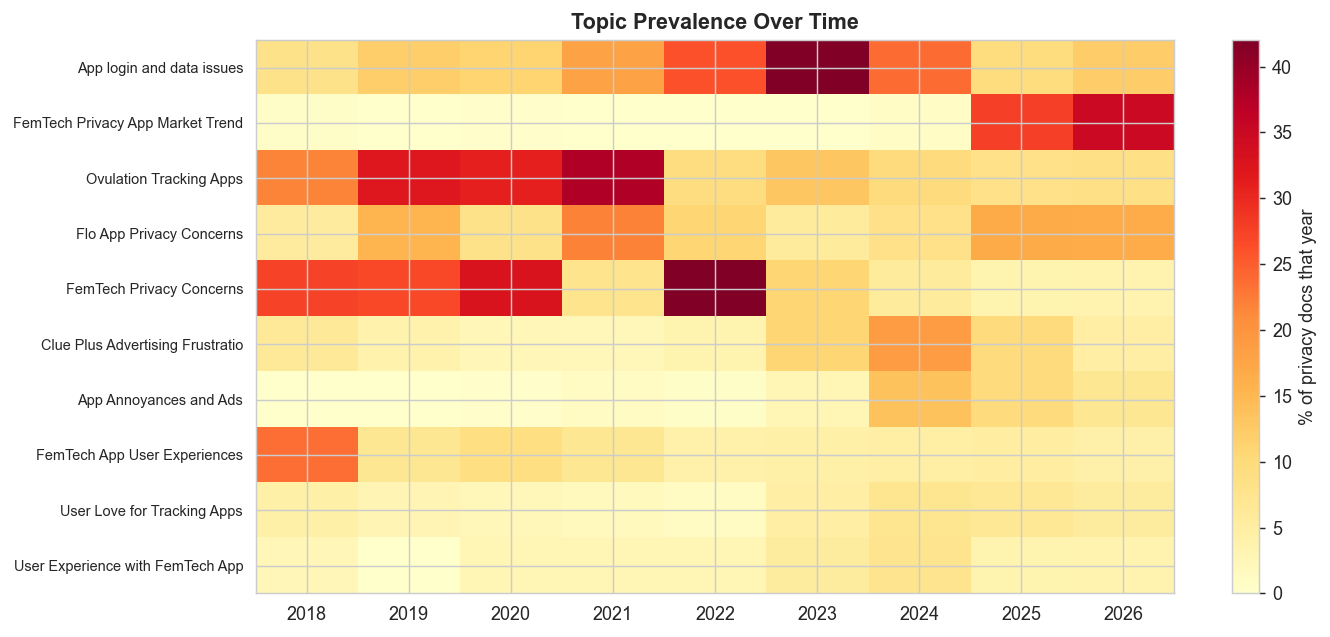

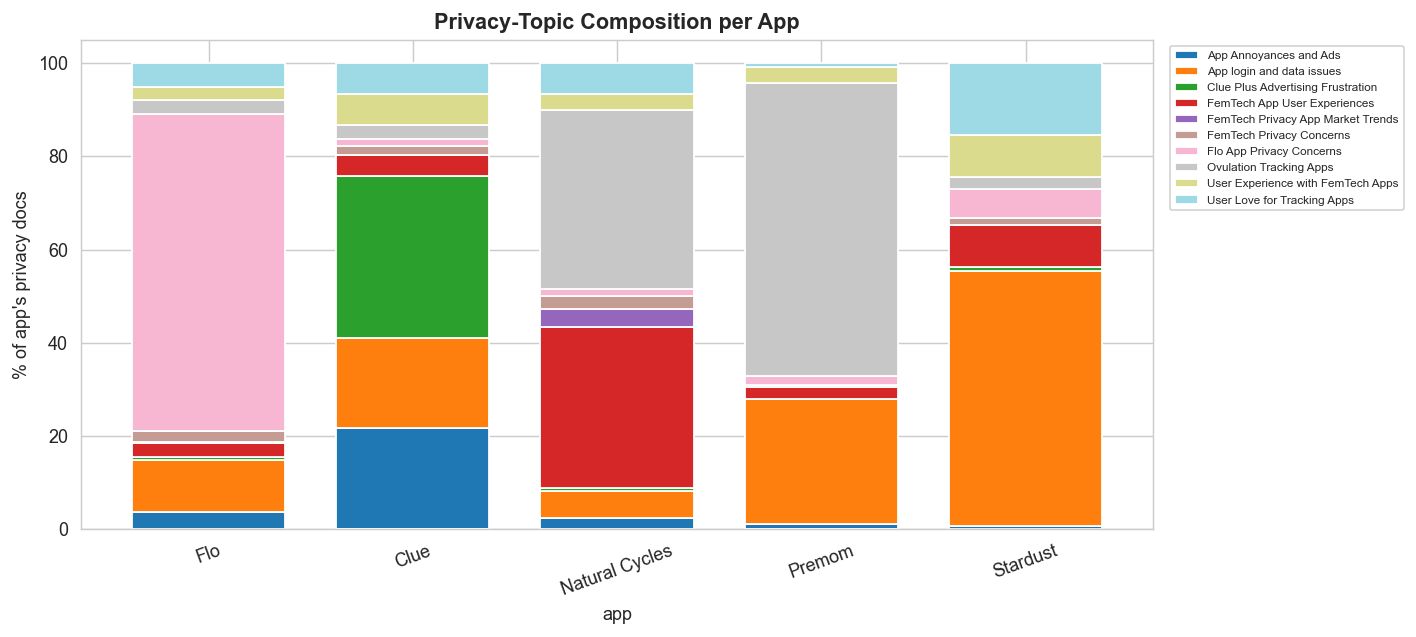

In [ ]:
# 8.D — Topic × time visualizations 
tt = df_top.merge(df_gpt[['text','sentiment_gpt']].drop_duplicates('text'), on='text', how='left')
tt = tt[tt['topic']!=-1].copy()
tt = tt[tt['topic_label']!='Natural Climate Cycles Discussion']   # FIX: drop off-topic noise
tt['app'] = clean_app(tt['label']); tt['yr'] = tt['date'].astype(str).str[:4]

top_labels = tt['topic_label'].value_counts().head(10).index.tolist()  # merge duplicate labels
tt10 = tt[tt['topic_label'].isin(top_labels)]
short = {L: L[:32] for L in top_labels}

# topic prevalence heatmap
yrs=[y for y in sorted(tt['yr'].unique()) if '2018'<=y<='2026']
M=np.array([[100*((tt10[tt10['yr']==y]['topic_label']==L).sum()/max(len(tt10[tt10['yr']==y]),1)) for y in yrs] for L in top_labels])
fig,ax=plt.subplots(figsize=(11,5)); im=ax.imshow(M,cmap='YlOrRd',aspect='auto')
ax.set_xticks(range(len(yrs))); ax.set_xticklabels(yrs); ax.set_yticks(range(len(top_labels))); ax.set_yticklabels([short[L] for L in top_labels],fontsize=8)
plt.colorbar(im,label='% of privacy docs that year'); ax.set_title('Topic Prevalence Over Time',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_topic_heatmap.png'),bbox_inches='tight'); plt.show()

# sentiment per topic
sp=tt10[tt10['sentiment_gpt'].isin(['positive','negative','neutral'])]
piv=sp.groupby(['topic_label','sentiment_gpt']).size().unstack(fill_value=0).reindex(top_labels)
piv.index=[short[L] for L in top_labels]
pct=piv.div(piv.sum(1),axis=0)[['negative','neutral','positive']]*100
fig,ax=plt.subplots(figsize=(10,5)); pct.plot(kind='barh',stacked=True,color=['#E63946','#cccccc','#2A9D8F'],ax=ax,width=0.8)
ax.invert_yaxis(); ax.set_xlabel('%'); ax.set_title('Sentiment Composition per Topic',fontweight='bold'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_sentiment_per_topic.png'),bbox_inches='tight'); plt.show()

# topics per app
ta=tt10[tt10['app'].isin(APPS)]
ap=ta.groupby(['app','topic_label']).size().unstack(fill_value=0).reindex(APPS); ap=ap.div(ap.sum(1),axis=0)*100
fig,ax=plt.subplots(figsize=(11,5)); ap.plot(kind='bar',stacked=True,ax=ax,colormap='tab20',width=0.75)
ax.set_ylabel("% of app's privacy docs"); ax.set_title('Privacy-Topic Composition per App',fontweight='bold')
ax.legend(bbox_to_anchor=(1.01,1),fontsize=6.5); ax.set_xticklabels(APPS,rotation=20)
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_topics_per_app.png'),bbox_inches='tight'); plt.show()

## Section 9: Extended Visualizations

In [ ]:
df_gpt['dt'] = pd.to_datetime(df_gpt['date'], errors='coerce')
df_gpt['app'] = clean_app(df_gpt['label'])
gg = df_gpt[df_gpt['sentiment_gpt'].isin(['positive','negative','neutral'])].dropna(subset=['dt']).copy()
gg['ym'] = gg['dt'].dt.to_period('M')

EVENTS_MARK = [('2018-08','Natural Cycles ASA'),('2019-02','Flo–Facebook (WSJ)'),
    ('2019-09',"Privacy Int'l"),('2021-01','Flo FTC'),('2022-06','Dobbs'),
    ('2022-07','Google location'),('2023-05','Premom FTC'),('2026-07','Stardust/Mozilla')]
EVENTS_STUDY = [('2018-08','Natural Cycles ASA'),('2019-02','Flo–Facebook (WSJ)'),
    ('2019-09',"Privacy Int'l"),('2021-01','Flo FTC'),('2022-06','Dobbs'),('2023-05','Premom FTC')]
print('Section 9 ready')

Section 9 ready


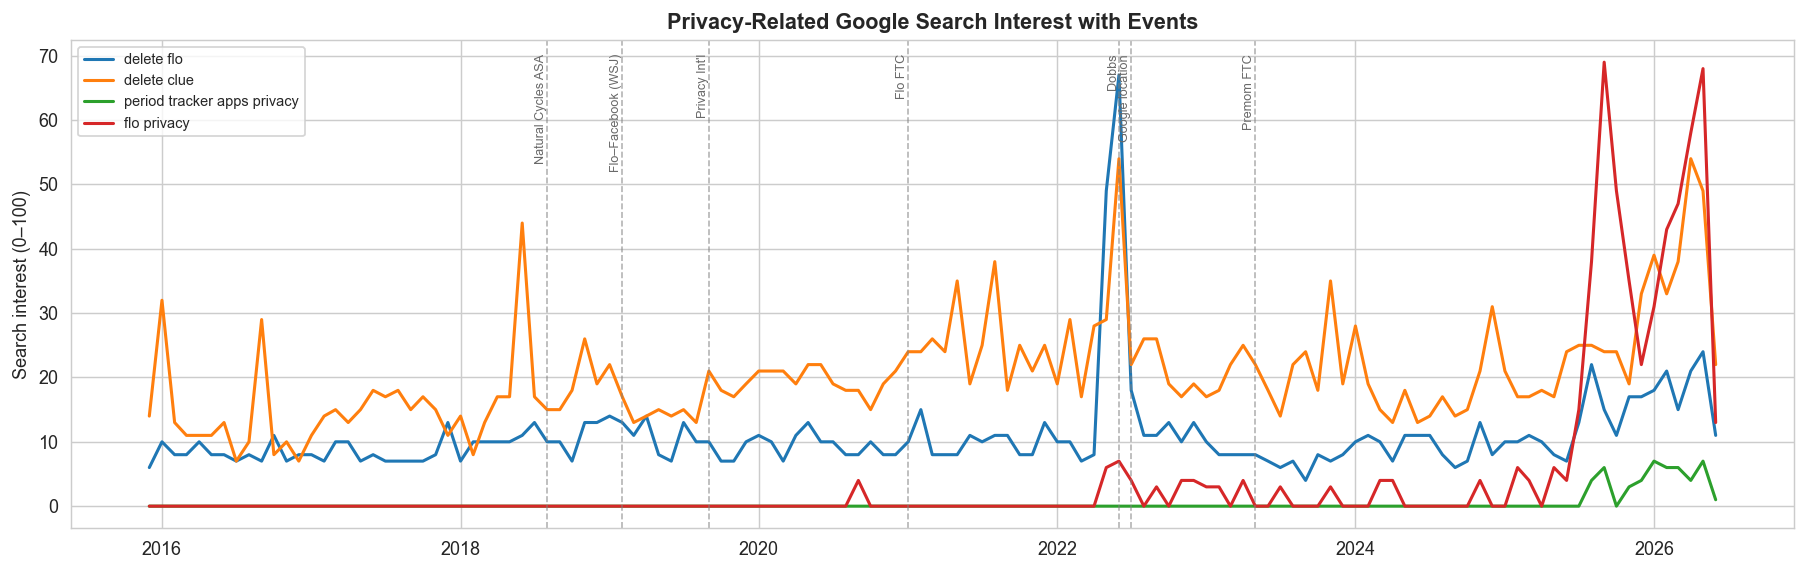

In [ ]:
# 9.A — Google Trends (public attention):
tr = pd.read_csv(os.path.join(THESIS,'google-trends1.csv')); tr['Time']=pd.to_datetime(tr['Time'])
fig,ax=plt.subplots(figsize=(14,4.5))
for col,c in [('delete flo','#E63946'),('delete clue','#457B9D'),
              ('period tracker apps privacy','#2A9D8F'),('flo privacy','#E9C46A')]:
    if col in tr.columns: ax.plot(tr['Time'],tr[col],label=col,lw=1.7)
ymax=ax.get_ylim()[1]
for ev,lbl in EVENTS_MARK:
    d=pd.to_datetime(ev+'-01')
    if tr['Time'].min()<=d<=tr['Time'].max():
        ax.axvline(d,color='gray',ls='--',lw=0.9,alpha=0.6)
        ax.text(d,ymax*0.97,lbl,rotation=90,fontsize=7,ha='right',va='top',color='dimgray')
ax.set_ylabel('Search interest (0–100)'); ax.legend(fontsize=8,loc='upper left')
ax.set_title('Privacy-Related Google Search Interest with Events',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_google_trends.png'),bbox_inches='tight'); plt.show()

             Event  before  after   Δ%
Natural Cycles ASA     502    822 64.0
Flo–Facebook (WSJ)     477    713 49.0
     Privacy Int'l     408    672 65.0
           Flo FTC     684   1106 62.0
             Dobbs     861   1659 93.0
        Premom FTC     553    989 79.0


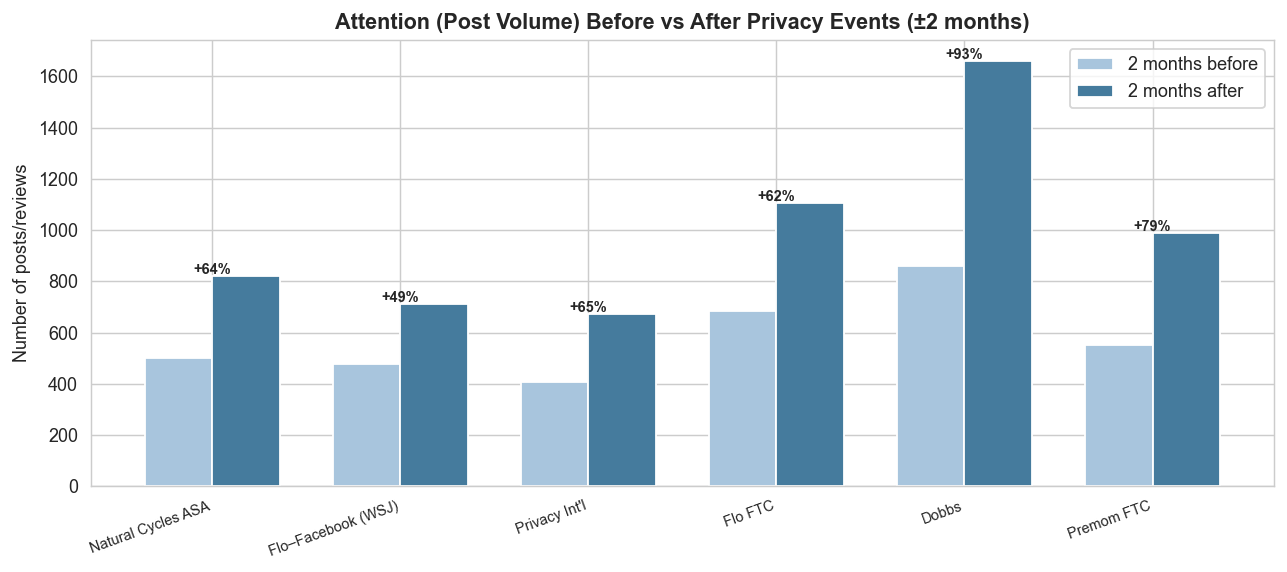

In [ ]:
# 9.B — Volume (attention) before/after events:
rows=[]
for ev,lbl in EVENTS_STUDY:
    e=pd.Period(ev,'M')
    vb=len(gg[(gg['ym']>=e-2)&(gg['ym']<=e-1)]); va=len(gg[(gg['ym']>=e)&(gg['ym']<=e+2)])
    rows.append({'Event':lbl,'before':vb,'after':va,'Δ%':round(100*(va-vb)/vb,0) if vb else np.nan})
vt=pd.DataFrame(rows); vt.to_csv(os.path.join(ADV,'volume_events.csv'),index=False); print(vt.to_string(index=False))
fig,ax=plt.subplots(figsize=(10,4.5)); x=np.arange(len(vt)); w=0.36
ax.bar(x-w/2,vt['before'],w,label='2 months before',color='#a8c5dd')
ax.bar(x+w/2,vt['after'],w,label='2 months after',color='#457B9D')
for i,rr in vt.iterrows():
    ax.annotate(f"{rr['Δ%']:+.0f}%",(i,max(rr['before'],rr['after'])+8),ha='center',fontweight='bold',fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(vt['Event'],rotation=20,ha='right',fontsize=8)
ax.set_ylabel('Number of posts/reviews'); ax.legend()
ax.set_title('Attention (Post Volume) Before vs After Privacy Events (±2 months)',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_volume_events.png'),bbox_inches='tight'); plt.show()

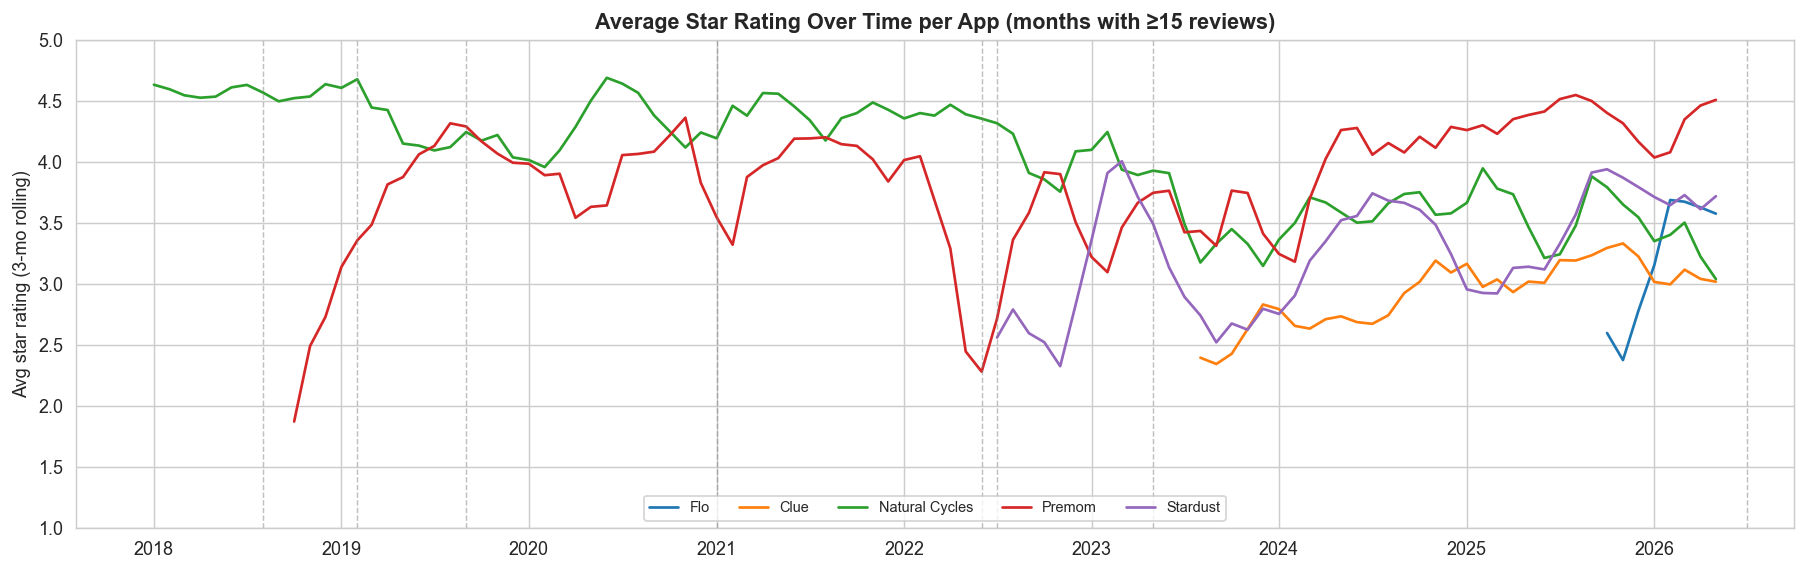

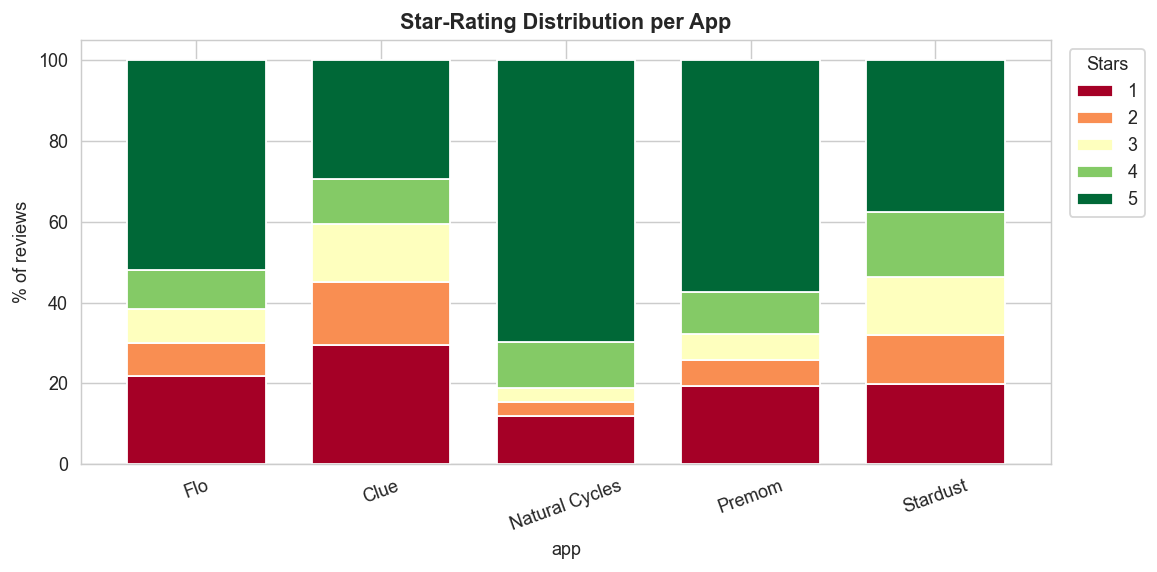

In [ ]:
# 9.C — Star-rating trends + distribution:
rev = df_gpt[df_gpt['data_source']!='twitter'].dropna(subset=['dt']).copy()
rev['m'] = rev['dt'].dt.to_period('M').dt.to_timestamp()
MIN = 15   # FIX: skip months with too few reviews (removes noisy early lines)
fig,ax=plt.subplots(figsize=(14,4.5))
for a in APPS:
    s=rev[rev['app']==a].groupby('m')['score'].agg(['mean','size'])
    s=s[(s['size']>=MIN)&(s.index>='2018-01-01')]['mean'].rolling(3,min_periods=1).mean()
    ax.plot(s.index,s.values,label=a,lw=1.5)
for ev,lbl in EVENTS_MARK: ax.axvline(pd.to_datetime(ev+'-01'),color='gray',ls='--',lw=0.8,alpha=0.5)
ax.set_ylabel('Avg star rating (3-mo rolling)'); ax.set_ylim(1,5); ax.legend(fontsize=8,ncol=5,loc='lower center')
ax.set_title('Average Star Rating Over Time per App (months with ≥15 reviews)',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_rating_trend.png'),bbox_inches='tight'); plt.show()

# rating distribution per app
dist=rev[rev['app'].isin(APPS)].groupby(['app','score']).size().unstack(fill_value=0).reindex(APPS)
dist=dist.div(dist.sum(1),axis=0)*100
fig,ax=plt.subplots(figsize=(9,4.5))
dist.plot(kind='bar',stacked=True,ax=ax,colormap='RdYlGn',width=0.75)
ax.set_ylabel('% of reviews'); ax.set_title('Star-Rating Distribution per App',fontweight='bold')
ax.legend(title='Stars',bbox_to_anchor=(1.01,1)); ax.set_xticklabels(APPS,rotation=20)
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_rating_dist.png'),bbox_inches='tight'); plt.show()

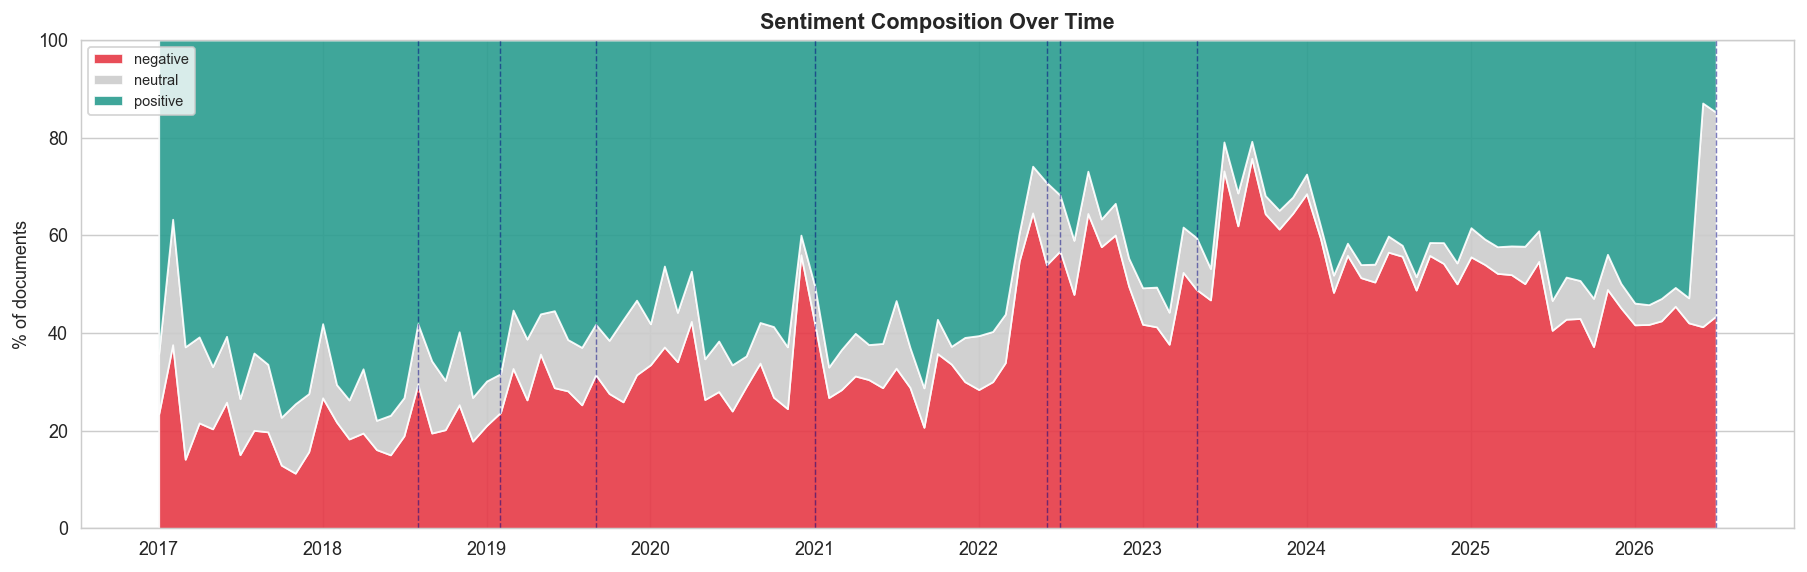

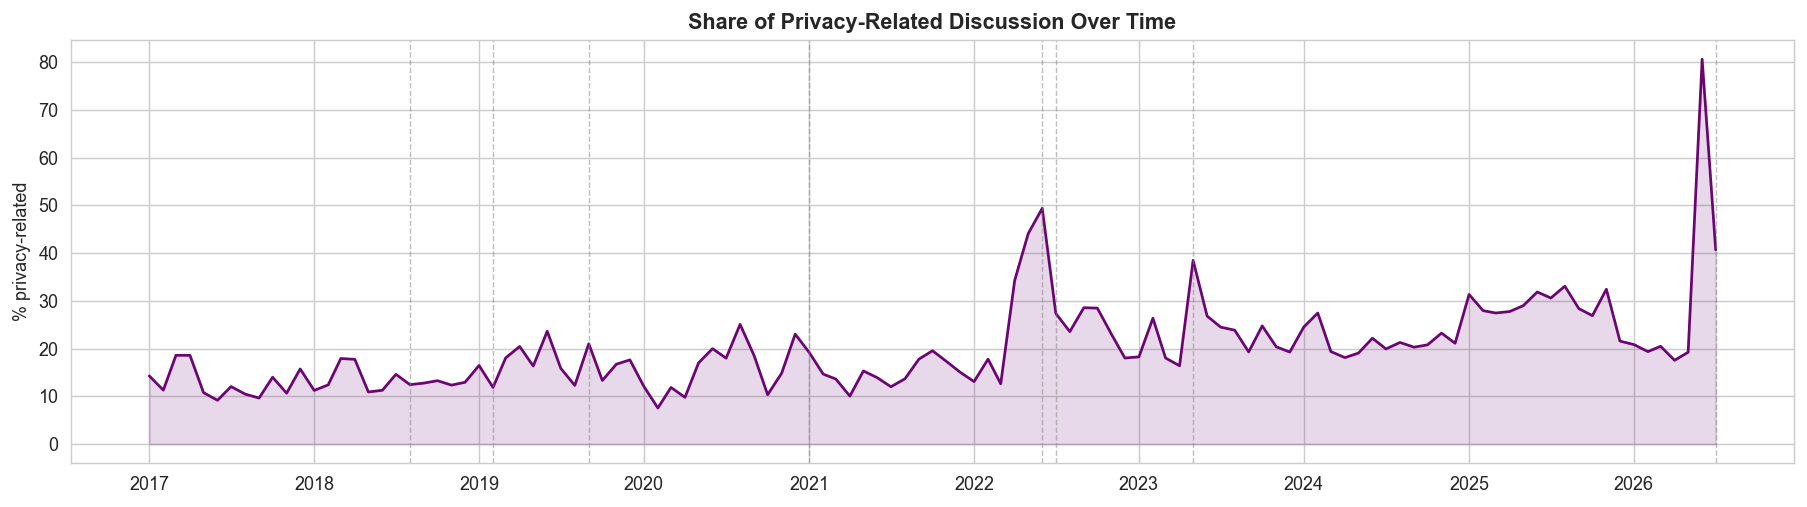

In [ ]:
# 9.D — Sentiment composition + privacy share over time:
comp=gg[gg['ym']>=pd.Period('2017-01','M')].groupby(['ym','sentiment_gpt']).size().unstack(fill_value=0)
pct=comp.div(comp.sum(1),axis=0)*100; idx=pct.index.to_timestamp()
fig,ax=plt.subplots(figsize=(14,4.5))
ax.stackplot(idx,pct['negative'],pct['neutral'],pct['positive'],
             labels=['negative','neutral','positive'],colors=['#E63946','#cccccc','#2A9D8F'],alpha=0.9)
for ev,lbl in EVENTS_MARK: ax.axvline(pd.to_datetime(ev+'-01'),color='navy',ls='--',lw=0.8,alpha=0.5)
ax.set_ylabel('% of documents'); ax.set_ylim(0,100); ax.legend(loc='upper left',fontsize=8)
ax.set_title('Sentiment Composition Over Time',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_sentiment_area.png'),bbox_inches='tight'); plt.show()
# privacy-talk share over time
PRIV=['privacy','data','tracking','share','sell','surveillance','trust','leak','breach','consent','third party','facebook','collect']
pr=df_gpt.dropna(subset=['dt']).copy(); pr['m']=pr['dt'].dt.to_period('M').dt.to_timestamp()
pr['priv']=pr['text'].astype(str).str.lower().apply(lambda t:any(k in t for k in PRIV))
sh=pr[pr['m']>='2017-01-01'].groupby('m')['priv'].mean()*100
fig,ax=plt.subplots(figsize=(14,4))
ax.plot(sh.index,sh.values,color='#6A0572',lw=1.5); ax.fill_between(sh.index,sh.values,alpha=0.15,color='#6A0572')
for ev,lbl in EVENTS_MARK: ax.axvline(pd.to_datetime(ev+'-01'),color='gray',ls='--',lw=0.8,alpha=0.5)
ax.set_ylabel('% privacy-related'); ax.set_title('Share of Privacy-Related Discussion Over Time',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_privacy_share.png'),bbox_inches='tight'); plt.show()

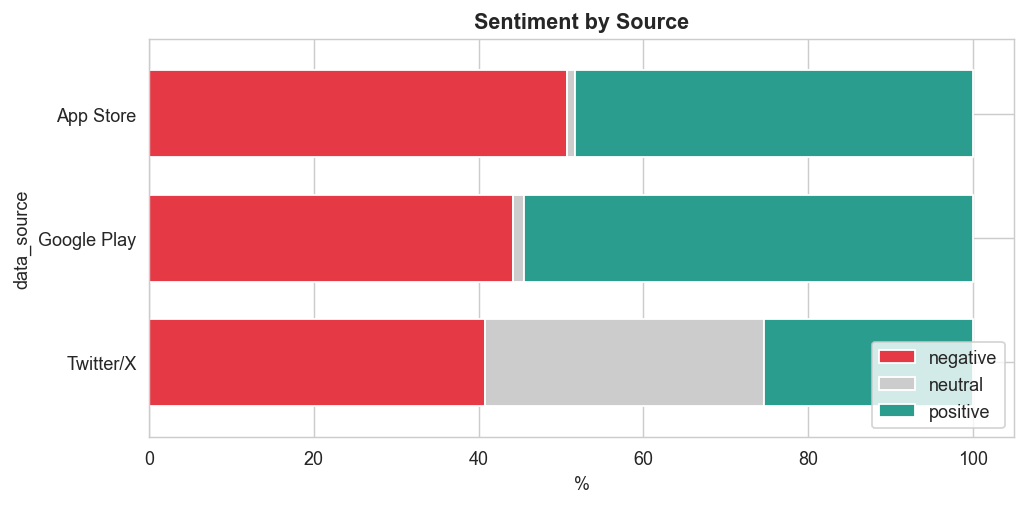

In [ ]:
# 9.E — Sentiment by source:
d=df_gpt[df_gpt['sentiment_gpt'].isin(['positive','negative','neutral'])]
piv=d.groupby(['data_source','sentiment_gpt']).size().unstack(fill_value=0)
pct=piv.div(piv.sum(1),axis=0)[['negative','neutral','positive']]*100
pct=pct.reindex(['twitter','google_play','app_store'])
fig,ax=plt.subplots(figsize=(8,4))
pct.plot(kind='barh',stacked=True,ax=ax,color=['#E63946','#cccccc','#2A9D8F'],width=0.7)
ax.set_xlabel('%'); ax.set_title('Sentiment by Source',fontweight='bold'); ax.legend(loc='lower right')
ax.set_yticklabels(['Twitter/X','Google Play','App Store'])
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_sentiment_by_source.png'),bbox_inches='tight'); plt.show()

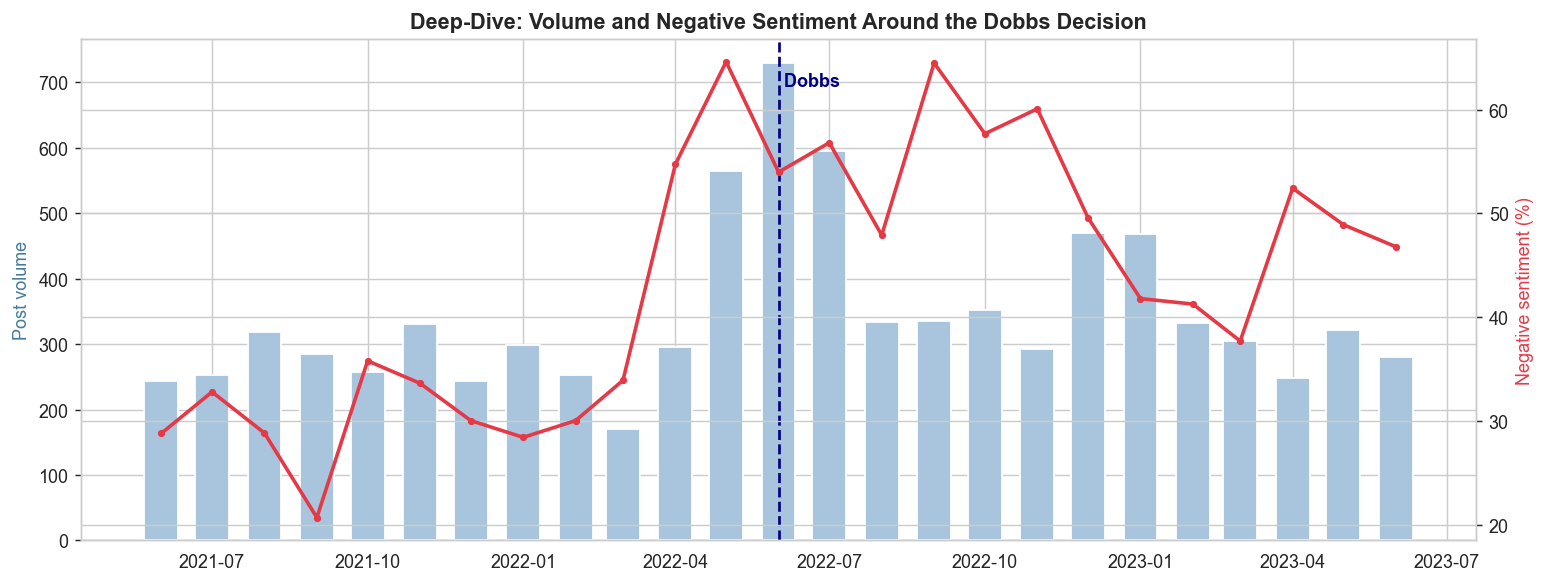

In [ ]:
# 9.F — Deep-dive: volume + negative sentiment around Dobbs (2021-06 … 2023-06)
win = gg[(gg['ym']>=pd.Period('2021-06','M')) & (gg['ym']<=pd.Period('2023-06','M'))]
vol = win.groupby('ym').size()
neg = win.groupby('ym')['sentiment_gpt'].apply(lambda s:100*(s=='negative').mean())
idx = vol.index.to_timestamp()
fig,ax1=plt.subplots(figsize=(12,4.6))
ax1.bar(idx,vol.values,width=20,color='#a8c5dd',label='Post volume'); ax1.set_ylabel('Post volume',color='#457B9D')
ax2=ax1.twinx(); ax2.plot(idx,neg.values,color='#E63946',lw=2,marker='o',ms=3,label='Negative %')
ax2.set_ylabel('Negative sentiment (%)',color='#E63946')
ax1.axvline(pd.to_datetime('2022-06-01'),color='navy',ls='--',lw=1.5)
ax1.text(pd.to_datetime('2022-06-01'),vol.max()*0.98,' Dobbs',color='navy',fontweight='bold',va='top')
ax1.set_title('Deep-Dive: Volume and Negative Sentiment Around the Dobbs Decision',fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_dobbs_deepdive.png'),bbox_inches='tight'); plt.show()

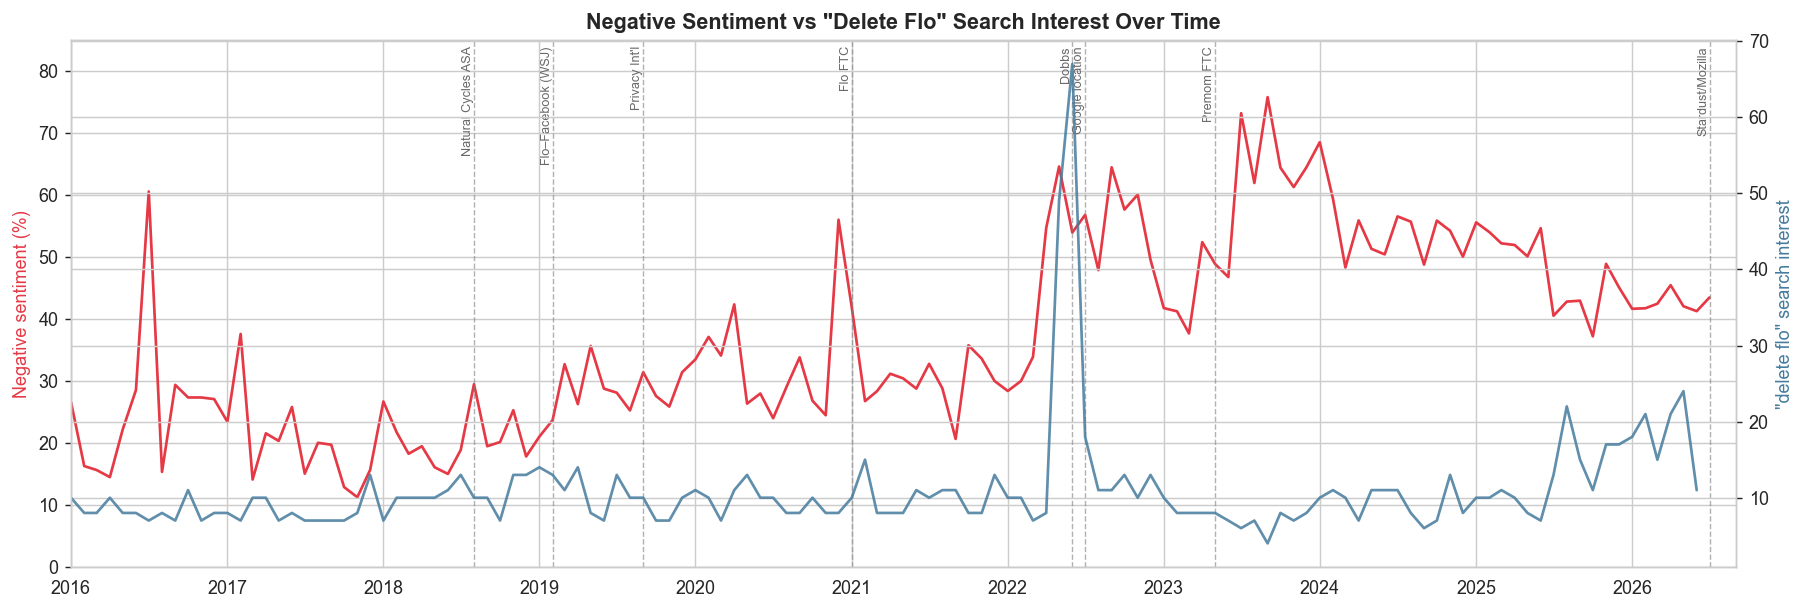

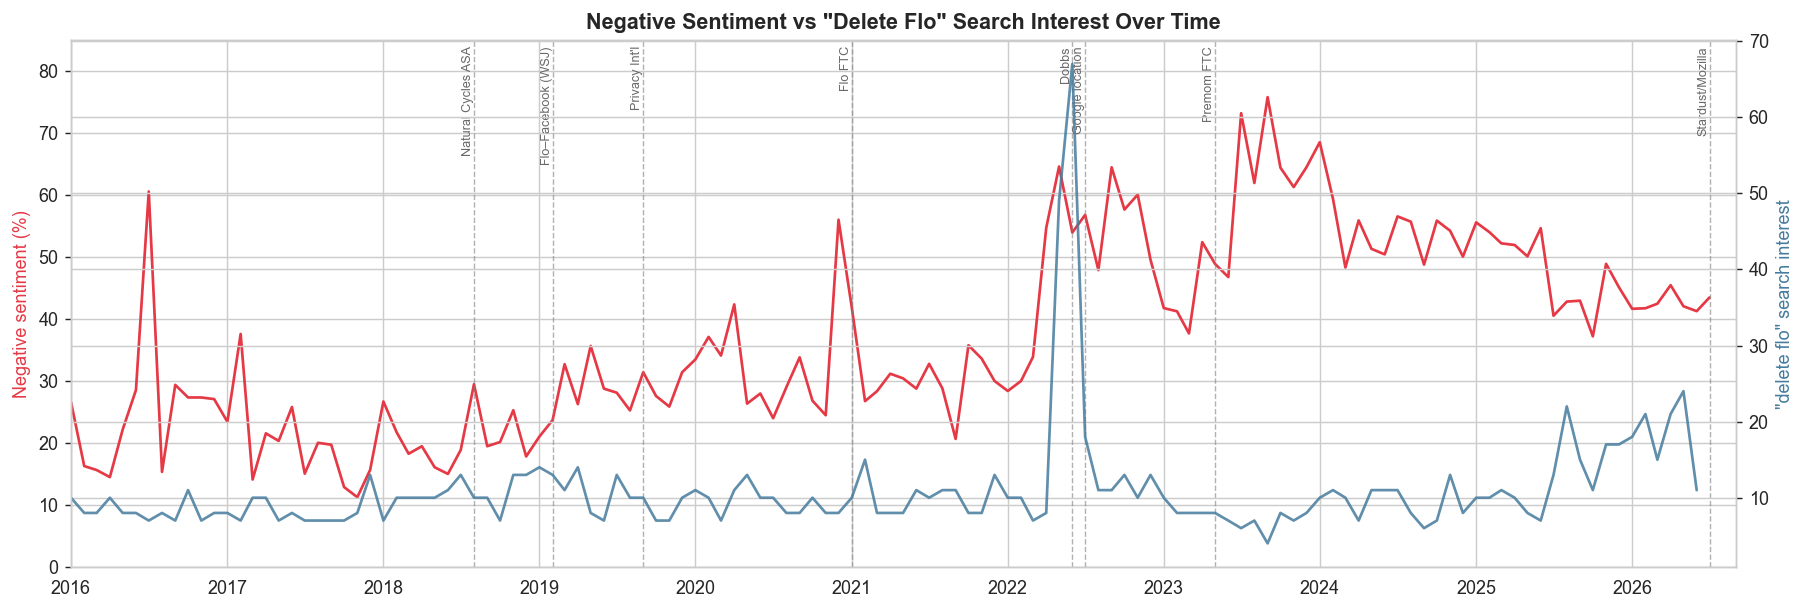

In [ ]:
# 9.G — Negative sentiment vs "delete flo" search interest (public attention vs tone)
MIN_DOCS = 30  # пропускаем разреженные ранние месяцы (иначе 0%/100% шум)

by_month = gg.groupby('ym')['sentiment_gpt']
neg_m = by_month.apply(lambda s: 100 * (s == 'negative').mean())
month_counts = by_month.size()
neg_m = neg_m[month_counts >= MIN_DOCS]
neg_m.index = neg_m.index.to_timestamp()

tr = pd.read_csv(os.path.join(THESIS, 'google-trends1.csv'))
tr['Time'] = pd.to_datetime(tr['Time'])

fig, ax1 = plt.subplots(figsize=(14, 4.8))
ax1.plot(neg_m.index, neg_m.values, color='#E63946', lw=1.5, label='Negative sentiment %')
ax1.set_ylabel('Negative sentiment (%)', color='#E63946')
ax1.set_ylim(0, 85)

ax2 = ax1.twinx()
ax2.plot(tr['Time'], tr['delete flo'], color='#457B9D', lw=1.5, alpha=0.85)
ax2.set_ylabel('"delete flo" search interest', color='#457B9D')

for ev, lbl in EVENTS_MARK:
    x = pd.to_datetime(ev + '-01')
    ax1.axvline(x, color='gray', ls='--', lw=0.8, alpha=0.6)
    ax1.text(x, 84, lbl, rotation=90, fontsize=7, color='dimgray', ha='right', va='top')

ax1.set_xlim(pd.to_datetime('2016-01-01'), pd.to_datetime('2026-09-01'))
ax1.set_title('Negative Sentiment vs "Delete Flo" Search Interest Over Time', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(ADV, 'fig_sentiment_vs_trends.png'), bbox_inches='tight')
plt.show()

## Section 10: FemTech Market Overview

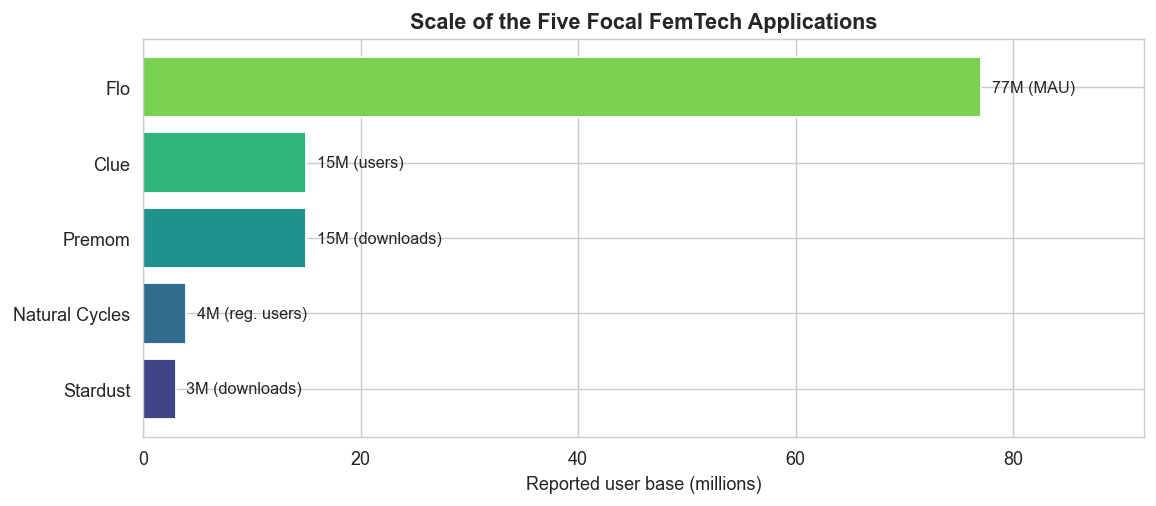

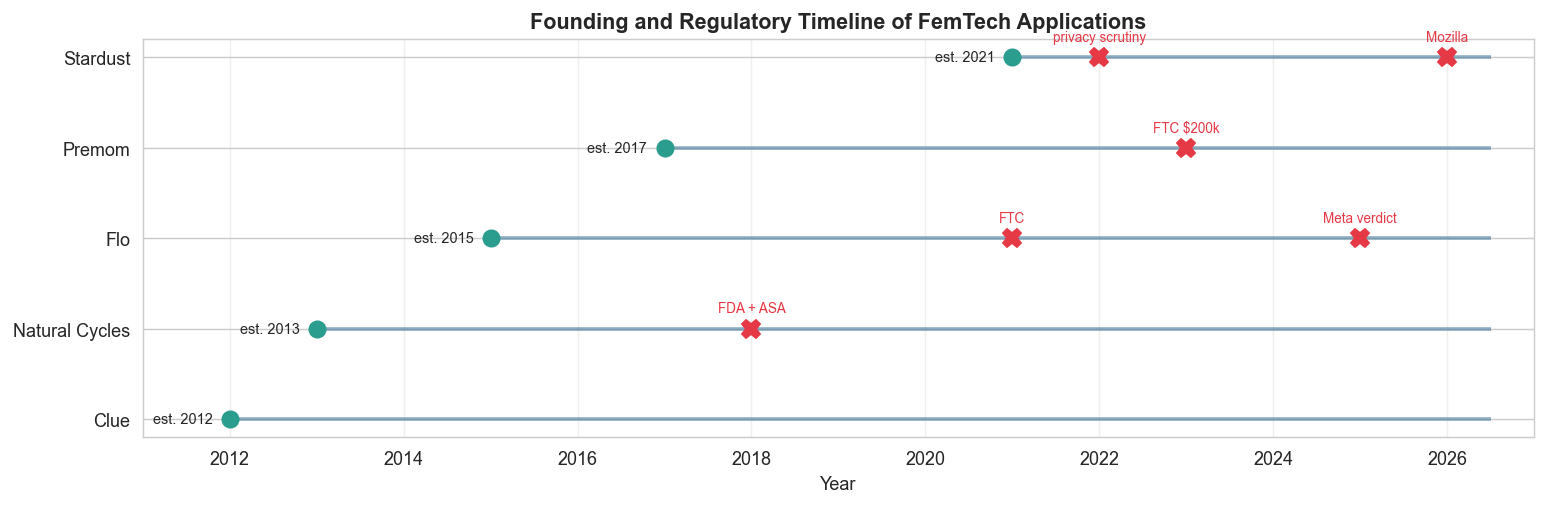

In [98]:
# --- Figure 1: reported user base per app ---
market = [
    ('Flo',            77, 'MAU'),
    ('Premom',         15, 'downloads'),
    ('Clue',           15, 'users'),
    ('Natural Cycles',  4, 'reg. users'),
    ('Stardust',        3, 'downloads'),
]
market.sort(key=lambda r: r[1])
names  = [m[0] for m in market]
vals   = [m[1] for m in market]
metric = [m[2] for m in market]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(names, vals, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(names))))
for bar, v, mt in zip(bars, vals, metric):
    ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f'{v}M ({mt})', va='center', fontsize=9)
ax.set_xlabel('Reported user base (millions)')
ax.set_xlim(0, 92)
ax.set_title('Scale of the Five Focal FemTech Applications', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ADV, 'fig_market_userbase.png'), bbox_inches='tight')
plt.show()

# --- Figure 2: founding + regulatory timeline ---
timeline = {
    'Flo':            {'founded': 2015, 'events': [(2021, 'FTC'), (2025, 'Meta verdict')]},
    'Clue':           {'founded': 2012, 'events': []},
    'Natural Cycles': {'founded': 2013, 'events': [(2018, 'FDA + ASA')]},
    'Premom':         {'founded': 2017, 'events': [(2023, 'FTC $200k')]},
    'Stardust':       {'founded': 2021, 'events': [(2022, 'privacy scrutiny'), (2026, 'Mozilla')]},
}
apps_order = ['Clue', 'Natural Cycles', 'Flo', 'Premom', 'Stardust']

fig, ax = plt.subplots(figsize=(12, 4))
for i, app in enumerate(apps_order):
    d = timeline[app]
    ax.hlines(i, d['founded'], 2026.5, color='#457B9D', lw=2, alpha=0.6)
    ax.plot(d['founded'], i, 'o', color='#2A9D8F', ms=9)
    ax.text(d['founded'] - 0.2, i, f"est. {d['founded']}", ha='right', va='center', fontsize=8)
    for yr, lbl in d['events']:
        ax.plot(yr, i, 'X', color='#E63946', ms=10)
        ax.text(yr, i + 0.18, lbl, ha='center', fontsize=7.5, color='#E63946')
ax.set_yticks(range(len(apps_order)))
ax.set_yticklabels(apps_order)
ax.set_xlim(2011, 2027)
ax.set_xlabel('Year')
ax.set_title('Founding and Regulatory Timeline of FemTech Applications', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(ADV, 'fig_market_timeline.png'), bbox_inches='tight')
plt.show()

In [5]:
# ===== QUICK RELOAD  =====
# Restores state from saved files — nothing heavy is recomputed.
import os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 140

THESIS  = os.path.expanduser('~/Desktop/thesis')
OUT_DIR = os.path.join(THESIS, 'final')
ADV     = os.path.join(OUT_DIR, 'adv')
os.makedirs(ADV, exist_ok=True)
POLICY_FILE = os.path.join(THESIS, 'raw_data', 'policy_scores.json')
OPENAI_API_KEY = 'YOUR_API_KEY'

# --- load the already-computed datasets (no recomputation) ---
df_gpt = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_gpt.csv'), low_memory=False)
df_top = pd.read_csv(os.path.join(OUT_DIR, 'femtech_with_topics.csv'), low_memory=False)
try:
    df_rob = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_roberta.csv'), low_memory=False)
except Exception:
    df_rob = None

# --- helpers & constants used by Sections 7–10 and the workarounds cells ---
def clean_app(s):
    return (s.astype(str)
            .str.replace(r'\s+\d{4}.*', '', regex=True)
            .str.replace(r'\s+Q[1-4].*', '', regex=True)
            .str.replace('NaturalCycles', 'Natural Cycles')
            .str.strip())

APPS = ['Flo', 'Clue', 'Natural Cycles', 'Premom', 'Stardust']
DIMS = ['data_collection_clarity', 'third_party_disclosure', 'user_control',
        'data_retention', 'legal_basis', 'plain_language']
DIM_LBL = ['Data collection', 'Third-party disc.', 'User control',
           'Data retention', 'Legal basis', 'Plain language']

df_gpt['app'] = clean_app(df_gpt['label'])
print(f'Reloaded: df_gpt {df_gpt.shape}, df_top {df_top.shape},',
      f'df_rob {None if df_rob is None else df_rob.shape}')
print('Ready ')

Reloaded: df_gpt (65322, 9), df_top (16542, 11), df_rob (65322, 9)
Ready 


In [6]:
# ===== Workarounds analysis (Federico's Q): do users suggest ways around the problem? =====
import re
import numpy as np
import matplotlib.pyplot as plt

ADV = os.path.join(OUT_DIR, 'adv')
os.makedirs(ADV, exist_ok=True)

wa = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_gpt.csv'), low_memory=False)
low = wa['text'].astype(str).str.lower()

PRIV = ['privacy', 'data', 'tracking', 'share', 'sell', 'surveillance', 'trust',
        'leak', 'breach', 'consent', 'third party', 'facebook', 'collect', 'sold']
priv_mask = low.apply(lambda s: any(k in s for k in PRIV))

WORK = (r"(switch(ed|ing)? to|use \w+ instead|better (app|alternative)|move[d]? to|"
        r"don.?t (put|enter|give|use) (real|my real|accurate|true)|fake (data|info|name|email|birth)|"
        r"lie about|burner|pen and paper|paper (calendar|method)|track.* manually|by hand|"
        r"vpn|opt.?out|turn off (location|tracking)|disable (location|tracking)|revoke|"
        r"offline|don.?t sync|export .* data|delete .* (and|then) (switch|use))")
work_mask = low.str.contains(WORK, regex=True, na=False)

cand = wa[priv_mask & work_mask].copy().reset_index(drop=True)
print(f'Privacy-relevant: {priv_mask.sum():,} | workaround candidates: {len(cand):,}')

/var/folders/pw/m0rkh2l51_b0zj4_25qwbjkw0000gp/T/ipykernel_1378/2632534189.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  work_mask = low.str.contains(WORK, regex=True, na=False)


Privacy-relevant: 14,341 | workaround candidates: 760


In [19]:
import json, time
from openai import OpenAI

client = OpenAI(api_key=OPENAI_API_KEY)
WA_DIR = os.path.join(OUT_DIR, 'workarounds')
os.makedirs(WA_DIR, exist_ok=True)

PROMPT = """A user wrote the following about a period/fertility tracking app. Does the user suggest a WORKAROUND to protect their privacy or avoid the data problem? Reply with ONE category:
- switch: recommends switching to / using a different app
- stop: says to delete or stop using tracking apps
- minimize: suggests entering fake or minimal data, or not giving real info
- manual: suggests tracking on paper / calendar / offline / spreadsheet
- technical: suggests a technical fix (VPN, turn off location, opt-out, revoke permissions, don't sync)
- none: no privacy workaround is suggested

Text: {text}

One word: switch, stop, minimize, manual, technical, or none."""

reqs = []
for i, txt in enumerate(cand['text'].astype(str)):
    body = {"model": "gpt-4o-mini",
            "messages": [{"role": "user", "content": PROMPT.format(text=txt[:500])}],
            "max_tokens": 3, "temperature": 0}
    reqs.append(json.dumps({"custom_id": str(i), "method": "POST",
                            "url": "/v1/chat/completions", "body": body}))
open(os.path.join(WA_DIR, 'req.jsonl'), 'w').write('\n'.join(reqs))

f = client.files.create(file=open(os.path.join(WA_DIR, 'req.jsonl'), 'rb'), purpose='batch')
batch = client.batches.create(input_file_id=f.id, endpoint='/v1/chat/completions', completion_window='24h')
print('submitted', batch.id)

while True:
    b = client.batches.retrieve(batch.id)
    print(b.status, b.request_counts)
    if b.status in ('completed', 'failed', 'expired', 'cancelled'):
        break
    time.sleep(30)

CATS = ('switch', 'stop', 'minimize', 'manual', 'technical', 'none')
labels = {}
if b.status == 'completed':
    for line in client.files.content(b.output_file_id).text.splitlines():
        if not line.strip():
            continue
        o = json.loads(line)
        raw = o['response']['body']['choices'][0]['message']['content'].strip().lower()
        labels[int(o['custom_id'])] = next((c for c in CATS if c in raw), 'none')
    cand['workaround'] = [labels.get(i, 'none') for i in range(len(cand))]
    cand.to_csv(os.path.join(WA_DIR, 'workarounds.csv'), index=False)
    print(cand['workaround'].value_counts().to_string())

submitted batch_6a73544d6cd48190acf56e347b654e38
validating BatchRequestCounts(completed=0, failed=0, total=0)
validating BatchRequestCounts(completed=0, failed=0, total=0)
validating BatchRequestCounts(completed=0, failed=0, total=0)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed=0, total=760)
in_progress BatchRequestCounts(completed=0, failed

KeyboardInterrupt: 

In [21]:
import json
from openai import OpenAI
client = OpenAI(api_key=OPENAI_API_KEY)

b = client.batches.retrieve('batch_6a734451fbd8819095e5859fdeeec88c')
print(b.status, b.request_counts)

CATS = ('switch', 'stop', 'minimize', 'manual', 'technical', 'none')
if b.status == 'completed':
    labels = {}
    for line in client.files.content(b.output_file_id).text.splitlines():
        if not line.strip():
            continue
        o = json.loads(line)
        raw = o['response']['body']['choices'][0]['message']['content'].strip().lower()
        labels[int(o['custom_id'])] = next((c for c in CATS if c in raw), 'none')
    cand['workaround'] = [labels.get(i, 'none') for i in range(len(cand))]
    cand.to_csv(os.path.join(OUT_DIR, 'workarounds', 'workarounds.csv'), index=False)
    print(cand['workaround'].value_counts().to_string())
else:
    print('ещё не готово — запусти эту ячейку попозже')

completed BatchRequestCounts(completed=760, failed=0, total=760)
workaround
none         452
switch       191
manual        60
stop          40
technical     14
minimize       3


Genuine workaround posts: 308 of 760 candidates


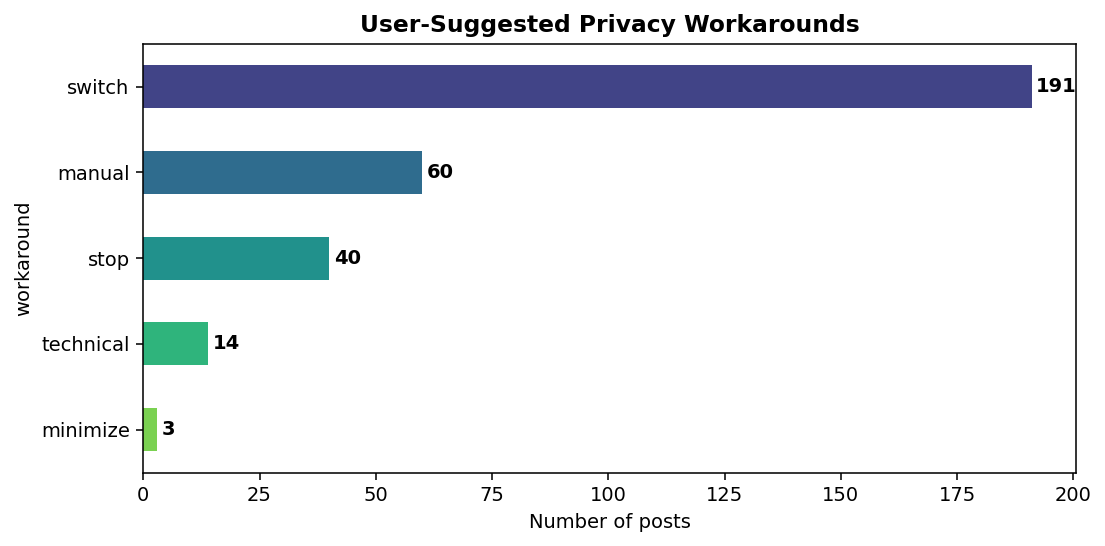


=== switch ===
 · I signed up for premium. Shortly afterwards my phone deleted the app & all my data was lost, even after signing in with google. All data lost. Thank goodness i still have
 · everything requires a subscription. im not paying for premium. so much clickbait. i will be switching to a new app. They also mine your data and store it in a cloud and t
 · I don't know. I really liked it until a while ago. It was great for tracking, and you could still get some interesting insights. Now everything except tracking is premium

=== manual ===
 · Holding my own data hostage I have multiple requests via their Ai Bot, which imo should be an option from the app directly, to export my data, responded to the support ac
 · Holding my own data hostage I have multiple requests via their Ai Bot, which imo should be an option from the app directly, to export my data, responded to the support ac
 · ETA: The copy-paste response of "We totally hear you. Pop ups can be disruptive and we know tha

In [22]:
wk = cand[cand['workaround'] != 'none']
print(f'Genuine workaround posts: {len(wk):,} of {len(cand):,} candidates')
dist = wk['workaround'].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind='barh', color=plt.cm.viridis(np.linspace(0.2, 0.8, len(dist))), ax=ax)
for i, v in enumerate(dist.values):
    ax.text(v + 1, i, str(v), va='center', fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('Number of posts')
ax.set_title('User-Suggested Privacy Workarounds', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ADV, 'fig_workarounds.png'), bbox_inches='tight')
plt.show()

for cat in dist.index:
    print(f'\n=== {cat} ===')
    for ex in wk[wk['workaround'] == cat]['text'].astype(str).head(3):
        print(' ·', ex[:170].replace(chr(10), ' '))

In [14]:
# ===== QUICK RELOAD =====
# Restores state from saved files — nothing heavy is recomputed.
import os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 140

THESIS  = os.path.expanduser('~/Desktop/thesis')
OUT_DIR = os.path.join(THESIS, 'final')
ADV     = os.path.join(OUT_DIR, 'adv')
os.makedirs(ADV, exist_ok=True)
POLICY_FILE = os.path.join(THESIS, 'raw_data', 'policy_scores.json')

# --- load the already-computed datasets (no recomputation) ---
df_gpt = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_gpt.csv'), low_memory=False)
df_top = pd.read_csv(os.path.join(OUT_DIR, 'femtech_with_topics.csv'), low_memory=False)
try:
    df_rob = pd.read_csv(os.path.join(OUT_DIR, 'femtech_sentiment_roberta.csv'), low_memory=False)
except Exception:
    df_rob = None

# --- helpers & constants used by Sections 7–10 and the workarounds cells ---
def clean_app(s):
    return (s.astype(str)
            .str.replace(r'\s+\d{4}.*', '', regex=True)
            .str.replace(r'\s+Q[1-4].*', '', regex=True)
            .str.replace('NaturalCycles', 'Natural Cycles')
            .str.strip())

APPS = ['Flo', 'Clue', 'Natural Cycles', 'Premom', 'Stardust']
DIMS = ['data_collection_clarity', 'third_party_disclosure', 'user_control',
        'data_retention', 'legal_basis', 'plain_language']
DIM_LBL = ['Data collection', 'Third-party disc.', 'User control',
           'Data retention', 'Legal basis', 'Plain language']

df_gpt['app'] = clean_app(df_gpt['label'])
print(f'Reloaded: df_gpt {df_gpt.shape}, df_top {df_top.shape},',
      f'df_rob {None if df_rob is None else df_rob.shape}')
print('Ready')

Reloaded: df_gpt (65322, 9), df_top (16542, 11), df_rob (65322, 9)
Ready


           App  SAY   DO   Gap  SAY_z  DO_z  Gap_z
           Flo 50.0 38.4  11.6   0.12 -0.61   0.73
          Clue 55.0 30.1  24.9   1.86 -1.32   3.18
Natural Cycles 48.3 64.8 -16.4  -0.47  1.66  -2.13
        Premom 46.7 49.4  -2.7  -1.03  0.34  -1.37
      Stardust 48.3 44.6   3.7  -0.47 -0.07  -0.40


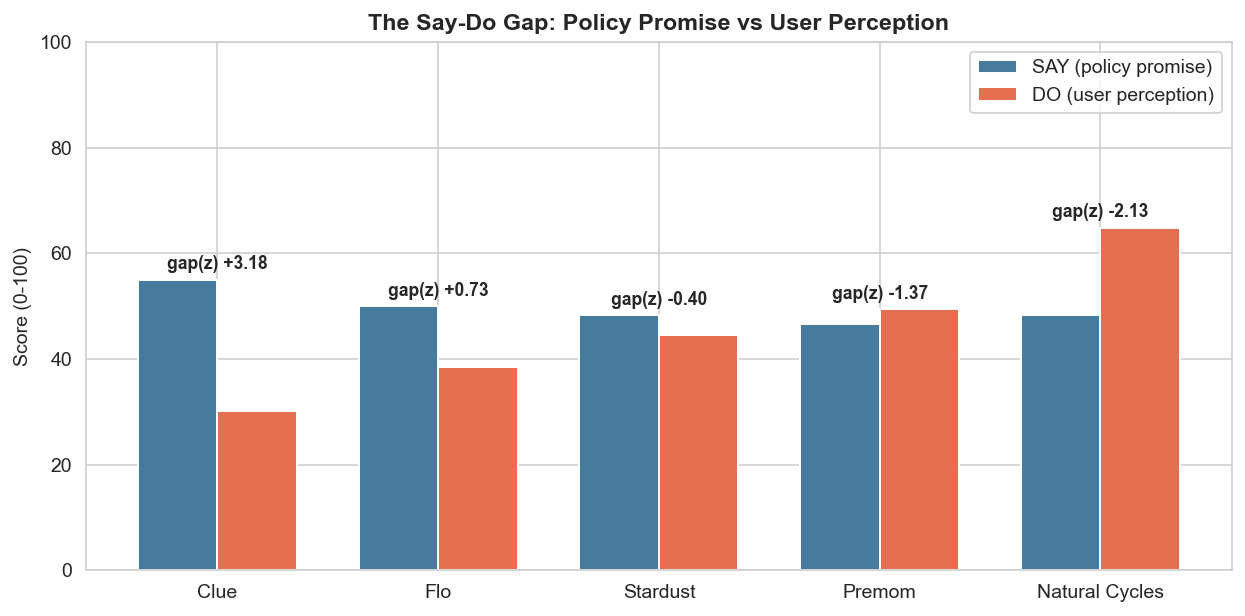

In [15]:
# ===== Say-Do Gap: z-score standardization (Federico's point 2) =====
saydo = pd.read_csv(os.path.join(ADV, 'say_do_gap.csv'))
say_col = [c for c in saydo.columns if 'say' in c.lower()][0]
do_col  = [c for c in saydo.columns if c.lower().startswith('do')][0]

z = lambda x: (x - x.mean()) / x.std(ddof=0)
saydo['SAY_z'] = z(saydo[say_col]).round(2)
saydo['DO_z']  = z(saydo[do_col]).round(2)
saydo['Gap_z'] = (saydo['SAY_z'] - saydo['DO_z']).round(2)
saydo.to_csv(os.path.join(ADV, 'say_do_gap.csv'), index=False)
print(saydo.to_string(index=False))

# re-plot: raw SAY vs DO bars, annotated with the standardized gap
order = saydo.sort_values('Gap_z', ascending=False).reset_index(drop=True)
x = np.arange(len(order)); w = 0.36
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w/2, order[say_col], w, label='SAY (policy promise)', color='#457B9D')
ax.bar(x + w/2, order[do_col],  w, label='DO (user perception)', color='#E76F51')
for i, gz in enumerate(order['Gap_z']):
    ax.annotate(f'gap(z) {gz:+.2f}',
                (i, max(order[say_col][i], order[do_col][i]) + 2),
                ha='center', fontweight='bold', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(order['App'])
ax.set_ylim(0, 100); ax.set_ylabel('Score (0-100)')
ax.set_title('The Say-Do Gap: Policy Promise vs User Perception', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ADV, 'fig_say_do_gap.png'), bbox_inches='tight')
plt.show()

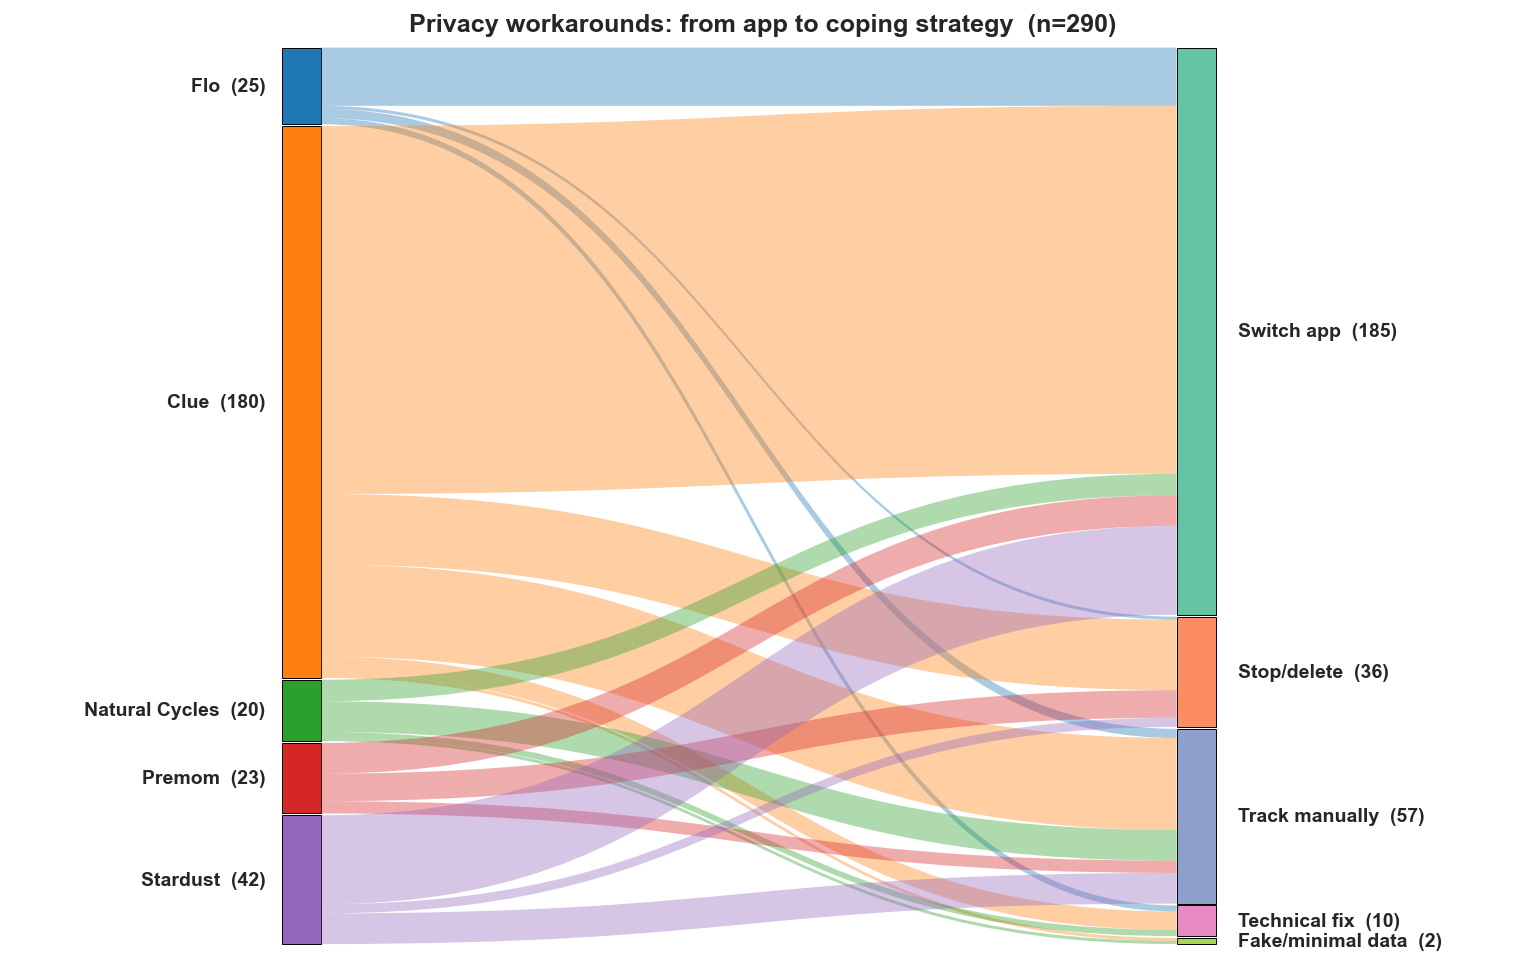

In [16]:
# ===== FIG: Privacy workarounds Sankey (FIXED — clean_app on labels) =====
from matplotlib.path import Path
import matplotlib.patches as patches
w = pd.read_csv(os.path.join(OUT_DIR, 'workarounds', 'workarounds.csv'))
w = w[w['workaround'] != 'none'].copy()
w['app'] = clean_app(w['label'])          # <-- fix: normalize 'NaturalCycles', 'Flo 2022 [Top]', etc.
CATS = ['switch','stop','manual','technical','minimize']
CATLBL = {'switch':'Switch app','stop':'Stop/delete','manual':'Track manually',
          'technical':'Technical fix','minimize':'Fake/minimal data'}
w = w[w['app'].isin(APPS) & w['workaround'].isin(CATS)]
M = w.groupby(['app','workaround']).size().unstack(fill_value=0).reindex(index=APPS, columns=CATS, fill_value=0)
apps = [a for a in APPS if M.loc[a].sum()>0]; cats = [c for c in CATS if M[c].sum()>0]
M = M.loc[apps, cats]; total = int(M.values.sum())
gap = 0.6; Ltot = M.sum(axis=1); Rtot = M.sum(axis=0)
fig, ax = plt.subplots(figsize=(11, 7)); ax.axis('off')
def blocks(tot, x, colors):
    ys = {}; pad = gap*(len(tot)-1); pos = total + pad
    for k in tot.index:
        h = tot[k]; pos -= h; ys[k] = (pos, h)
        ax.add_patch(patches.Rectangle((x,pos), 0.35, h, color=colors[k], ec='black', lw=0.5)); pos -= gap
    return ys
appc = {a: plt.cm.tab10(i) for i,a in enumerate(APPS)}
catc = {c: plt.cm.Set2(i) for i,c in enumerate(CATS)}
Ly = blocks(Ltot, 0.0, appc); Ry = blocks(Rtot, 8.0, catc)
for a in apps:
    p,h = Ly[a]; ax.text(-0.15, p+h/2, f'{a}  ({int(Ltot[a])})', ha='right', va='center', fontsize=10, fontweight='bold')
for c in cats:
    p,h = Ry[c]; ax.text(8.55, p+h/2, f'{CATLBL[c]}  ({int(Rtot[c])})', ha='left', va='center', fontsize=10, fontweight='bold')
loff = {a: Ly[a][0]+Ly[a][1] for a in apps}; roff = {c: Ry[c][0]+Ry[c][1] for c in cats}
for a in apps:
    for c in cats:
        v = M.loc[a,c]
        if v <= 0: continue
        y0t=loff[a]; y0b=loff[a]-v; loff[a]-=v; y1t=roff[c]; y1b=roff[c]-v; roff[c]-=v
        xm = (0.35+8.0)/2
        verts = [(0.35,y0t),(xm,y0t),(xm,y1t),(8.0,y1t),(8.0,y1b),(xm,y1b),(xm,y0b),(0.35,y0b),(0.35,y0t)]
        codes = [Path.MOVETO,Path.CURVE4,Path.CURVE4,Path.CURVE4,Path.LINETO,Path.CURVE4,Path.CURVE4,Path.CURVE4,Path.CLOSEPOLY]
        ax.add_patch(patches.PathPatch(Path(verts,codes), facecolor=appc[a], alpha=0.38, edgecolor='none'))
ax.set_xlim(-2.4, 11.0); ax.set_ylim(-1, total+gap*len(apps)+1)
ax.set_title('Privacy workarounds: from app to coping strategy  (n=%d)'%total, fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV, 'fig_workarounds_sankey.png'), dpi=150, bbox_inches='tight'); plt.show()

In [19]:
# ===== SURVEY: merge EN/IT, translate answers, normalize country =====
import os, pandas as pd, numpy as np
THESIS  = os.path.expanduser('~/Desktop/thesis')
OUT_DIR = os.path.join(THESIS, 'final'); ADV = os.path.join(OUT_DIR, 'adv'); os.makedirs(ADV, exist_ok=True)

df = pd.read_csv(os.path.join(THESIS, 'survey_raw.csv')); C = list(df.columns)
PAIRS = {'age':(2,25),'country':(3,26),'use':(4,27),'apps':(5,28),'howlong':(6,29),
 'reasons':(7,30),'datatypes':(8,31),'stop_reason':(9,32),'sensitive':(10,33),
 'q9_period':(11,34),'q9_mood':(12,35),'q9_sex':(13,36),'q9_health':(14,37),'q9_weight':(15,38),
 'read_policy':(16,39),'know_3p':(17,40),'scandal':(18,41),'trust':(19,42),
 'sell_action':(20,43),'switch_breach':(21,44),'changed':(22,45),'unaware':(23,46),'open_comment':(24,47)}
surv = pd.DataFrame()
surv['lang'] = np.where(df[C[1]].astype(str).str.contains('Italiano'),'IT','EN')
for name,(qi,di) in PAIRS.items():
    surv[name] = df[C[qi]].combine_first(df[C[di]])

MAP = {
 'use':{'Sì, la uso attualmente':'Yes, I currently use one','No, mai':'No, never',"L'ho usata in passato ma ho smesso":'I used one in the past but stopped'},
 'howlong':{'Da 6 mesi a 2 anni':'6 months – 2 years','Più di 4 anni':'More than 4 years','Da 2 a 4 anni':'2–4 years','Meno di 6 mesi':'Less than 6 months'},
 'sensitive':{'Non particolarmente sensibili':'Not particularly sensitive','Sì, molto sensibili':'Yes, very sensitive','Abbastanza sensibili':'Somewhat sensitive','Per niente sensibili':'Not sensitive at all'},
 'read_policy':{"L'ho accettata senza leggerla":'I accepted it without reading',"Sì, l'ho letta per intero":'Yes, I read it fully','Non ricordo':"I don't remember","L'ho scorsa / letta parzialmente":'I skimmed / partially read it'},
 'know_3p':{'Lo sospettavo ma non ne ero sicura':"I suspected but wasn't sure",'Sì, ne ero pienamente consapevole':'Yes, I was fully aware','No, non lo sapevo':"No, I didn't know this"},
 'scandal':{'No, non ne ho mai sentito parlare':"No, I haven't heard of any",'Sì, conosco i dettagli':'Yes, I know the details','Ne ho sentito parlare ma so poco':"I've heard something but don't know much"},
 'trust':{'Neutrale':'Neutral','Mi fido abbastanza':'Mostly trust it','Non mi fido molto':'Mostly distrust it','Mi fido completamente':'Completely trust it','Non mi fido per niente':'Do not trust it at all'},
 'sell_action':{'Continuerei a usarla — non mi disturba':"Continue using it — it doesn't bother me",'Modificherei le impostazioni ma continuerei a usarla':'Change my privacy settings but keep using it',"Eliminerei l'app immediatamente":'Delete the app immediately',"Cercherei un'alternativa più rispettosa della privacy":'Look for a more privacy-focused alternative','Non sono sicura':"I'm not sure"},
 'switch_breach':{'Dipende dalla gravità':'It depends on the severity','Probabilmente no':'Probably not','Sì, sicuramente':'Yes, definitely','Probabilmente sì':'Probably yes','No, continuerei a usarla':'No, I would keep using it'},
 'changed':{'No, non me lo sono mai chiesta':'No, it never crossed my mind','Sì':'Yes','No, ma ci ho pensato':'No, but I considered it'},
 'unaware':{'Forse':'Possibly','Sì, sicuramente':'Yes, definitely','Non ci ho mai pensato':"I haven't thought about it",'No, sono ben informata sui rischi':"No, I'm well-informed about the risks"}}
for col,m in MAP.items(): surv[col] = surv[col].replace(m)

opt_map = {'Per tenere traccia del ciclo / sapere quando arriva':"To keep track of my period / know when it's coming",
 "Per monitorare l'ovulazione e la fertilità (cercando di concepire)":'To track ovulation and fertility (trying to conceive)',
 'Per evitare una gravidanza (metodo di consapevolezza della fertilità)':'To avoid pregnancy (fertility awareness method)',
 "Per monitorare l'attività sessuale":'To track sexual activity','Per monitorare PMS / umore / sintomi durante il ciclo':'To track PMS / mood / symptoms throughout my cycle',
 'Motivi medici (es. PCOS, endometriosi)':'Medical reasons (e.g. PCOS, endometriosis)','Per curiosità / autoconoscenza':'Out of curiosity / self-knowledge',
 'Date di inizio/fine del ciclo':'Period start/end dates','Sintomi o dolore':'Symptoms or pain','Umore / emozioni':'Mood / emotions',
 'Attività sessuale':'Sexual activity','Peso / temperatura corporea':'Body weight / temperature','Il mio calendario':'My calendar'}
def tr_multi(v):
    if pd.isna(v): return v
    return ';'.join(opt_map.get(p.strip(), p.strip()) for p in str(v).split(';'))
for col in ['reasons','datatypes','apps']: surv[col] = surv[col].map(tr_multi)

def norm_country(v):
    if pd.isna(v): return v
    s = str(v).strip().lower()
    if any(k in s for k in ['ital','padova','venezia','castiglione','padua']): return 'Italy'
    if 'russia/germany' in s: return 'Germany'
    if 'russia' in s or s in ('rus','ru'): return 'Russia'
    if 'kazakh' in s: return 'Kazakhstan'
    if 'poland' in s: return 'Poland'
    if 'german' in s: return 'Germany'
    if 'belg' in s: return 'Belgium'
    if 'türk' in s or 'turk' in s: return 'Turkey'
    if 'israel' in s: return 'Israel'
    if 'ucrain' in s or 'ukrain' in s: return 'Ukraine'
    if s in ('usa','us','u.s.','u.s.a.','america') or 'united states' in s: return 'United States'
    if s in ('england','uk','u.k.','britain'): return 'United Kingdom'
    return s.title()
surv['country'] = surv['country'].map(norm_country)

surv.to_csv(os.path.join(ADV, 'survey_clean.csv'), index=False)
print('Clean survey:', surv.shape, '| lang:', dict(surv['lang'].value_counts()))
print(surv['country'].value_counts().to_string())

Clean survey: (101, 24) | lang: {'EN': np.int64(75), 'IT': np.int64(26)}
country
Italy             41
Kazakhstan        17
Russia            13
Turkey             9
United States      5
Germany            4
Israel             3
Poland             2
Belgium            1
United Kingdom     1
Azerbaijan         1
Uzbekistan         1
Ireland            1
France             1
Ukraine            1


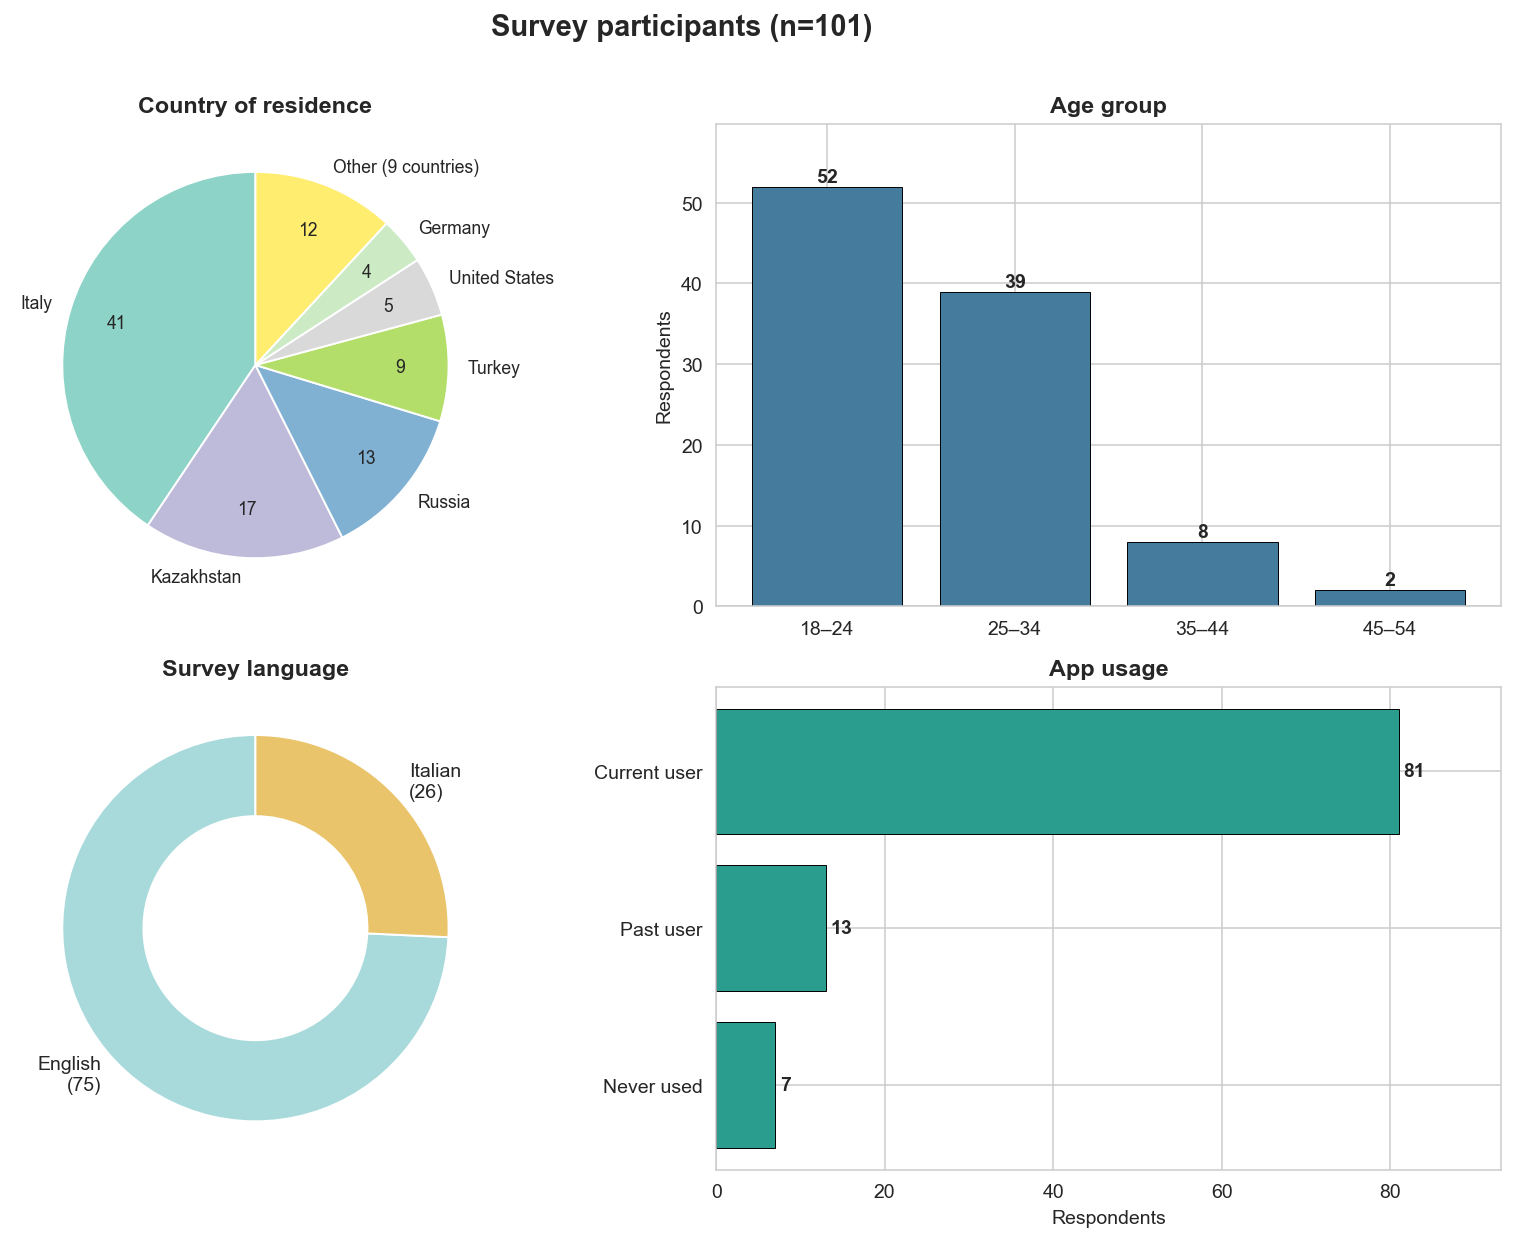

In [24]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd, os
d = pd.read_csv(os.path.join(ADV, 'survey_clean.csv')); N = len(d)
fig,axes=plt.subplots(2,2,figsize=(12,9))
# (a) country pie: top 6 + Other
cc=d['country'].value_counts(); top=cc.head(6); other=cc.iloc[6:].sum()
pie_vals=list(top.values)+[other]; pie_lab=list(top.index)+[f'Other ({(cc.iloc[6:]>0).sum()} countries)']
axes[0,0].pie(pie_vals,labels=pie_lab,autopct=lambda p:f'{p*N/100:.0f}',startangle=90,
              colors=plt.cm.Set3(np.linspace(0,1,len(pie_vals))),textprops={'fontsize':9},pctdistance=0.75)
axes[0,0].set_title('Country of residence',fontsize=12,fontweight='bold')
# (b) age
order=['18–24','25–34','35–44','45–54']; ac=d['age'].value_counts().reindex(order,fill_value=0)
axes[0,1].bar(range(len(ac)),ac.values,color='#457B9D',edgecolor='black',lw=0.5)
for i,v in enumerate(ac.values): axes[0,1].text(i,v+0.6,str(v),ha='center',fontweight='bold')
axes[0,1].set_xticks(range(len(order))); axes[0,1].set_xticklabels(order); axes[0,1].set_ylim(0,max(ac.values)*1.15)
axes[0,1].set_ylabel('Respondents'); axes[0,1].set_title('Age group',fontsize=12,fontweight='bold')
# (c) language donut
lc=d['lang'].value_counts(); lab=['English' if k=='EN' else 'Italian' for k in lc.index]
axes[1,0].pie(lc.values,labels=[f'{l}\n({v})' for l,v in zip(lab,lc.values)],startangle=90,
              colors=['#a8dadc','#e9c46a'],wedgeprops=dict(width=0.42),textprops={'fontsize':10})
axes[1,0].set_title('Survey language',fontsize=12,fontweight='bold')
# (d) usage
um={'Yes, I currently use one':'Current user','I used one in the past but stopped':'Past user','No, never':'Never used'}
uc=d['use'].map(um).value_counts().reindex(['Current user','Past user','Never used'],fill_value=0)
axes[1,1].barh(range(len(uc)),uc.values,color='#2a9d8f',edgecolor='black',lw=0.5)
for i,v in enumerate(uc.values): axes[1,1].text(v+0.6,i,str(v),va='center',fontweight='bold')
axes[1,1].set_yticks(range(len(uc))); axes[1,1].set_yticklabels(uc.index); axes[1,1].invert_yaxis()
axes[1,1].set_xlim(0,max(uc.values)*1.15); axes[1,1].set_xlabel('Respondents'); axes[1,1].set_title('App usage',fontsize=12,fontweight='bold')
fig.suptitle(f'Survey participants (n={N})',fontsize=15,fontweight='bold')
plt.tight_layout(rect=[0,0,1,0.97])
plt.savefig(os.path.join(ADV,'fig_survey_demographics.png'),dpi=150,bbox_inches='tight'); plt.show()

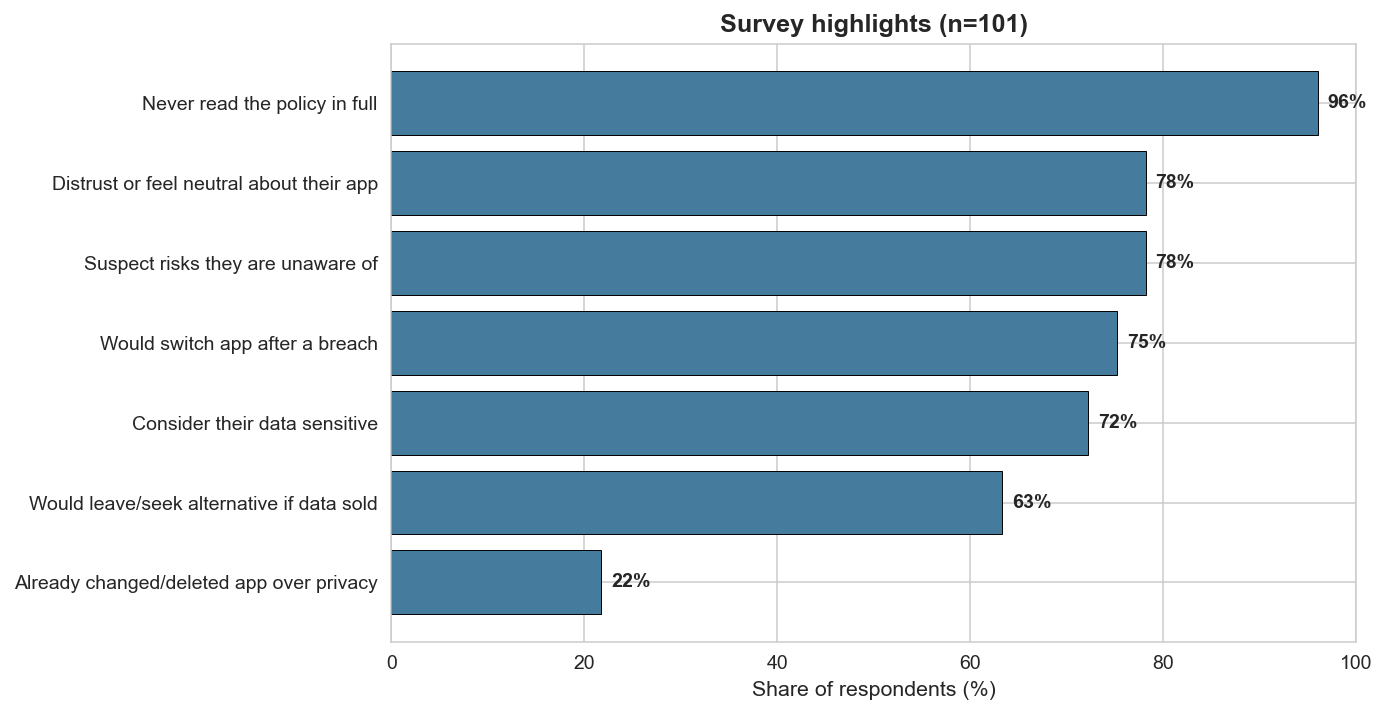

In [20]:
import matplotlib.pyplot as plt
d = pd.read_csv(os.path.join(ADV, 'survey_clean.csv')); N = len(d)
def pct(col, vals): return d[col].isin(vals).mean()*100
items = [('Consider their data sensitive', pct('sensitive',['Yes, very sensitive','Somewhat sensitive'])),
 ('Never read the policy in full', (d['read_policy']!='Yes, I read it fully').mean()*100),
 ('Suspect risks they are unaware of', pct('unaware',['Yes, definitely','Possibly'])),
 ('Would switch app after a breach', pct('switch_breach',['Yes, definitely','Probably yes'])),
 ('Would leave/seek alternative if data sold', pct('sell_action',['Look for a more privacy-focused alternative','Delete the app immediately'])),
 ('Distrust or feel neutral about their app', pct('trust',['Mostly distrust it','Do not trust it at all','Neutral'])),
 ('Already changed/deleted app over privacy', pct('changed',['Yes']))]
labels=[i[0] for i in items]; vals=[i[1] for i in items]
o=np.argsort(vals); labels=[labels[i] for i in o]; vals=[vals[i] for i in o]
fig,ax=plt.subplots(figsize=(10,5.2))
ax.barh(range(len(vals)), vals, color='#457B9D', edgecolor='black', lw=0.5)
for i,v in enumerate(vals): ax.text(v+1,i,f'{v:.0f}%',va='center',fontweight='bold',fontsize=10)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels,fontsize=10)
ax.set_xlim(0,100); ax.set_xlabel('Share of respondents (%)',fontsize=11)
ax.set_title(f'Survey highlights (n={N})',fontsize=13,fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_survey_highlights.png'),dpi=150,bbox_inches='tight'); plt.show()

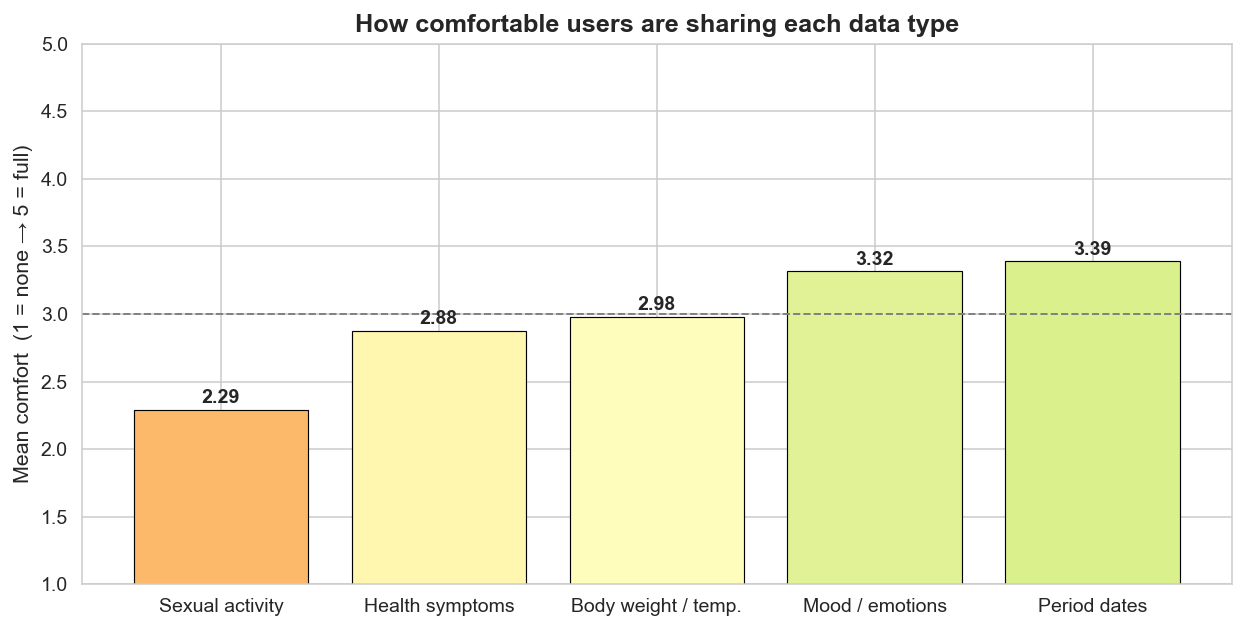

In [21]:
q9={'Period dates':'q9_period','Mood / emotions':'q9_mood','Body weight / temp.':'q9_weight','Health symptoms':'q9_health','Sexual activity':'q9_sex'}
means={k:pd.to_numeric(d[v],errors='coerce').mean() for k,v in q9.items()}
ks=sorted(means,key=means.get)
fig,ax=plt.subplots(figsize=(9,4.6))
cols=plt.cm.RdYlGn((np.array([means[k] for k in ks])-1)/4)
ax.bar(range(len(ks)),[means[k] for k in ks],color=cols,edgecolor='black',lw=0.6)
for i,k in enumerate(ks): ax.text(i,means[k]+0.05,f'{means[k]:.2f}',ha='center',fontweight='bold')
ax.set_xticks(range(len(ks))); ax.set_xticklabels(ks,fontsize=10)
ax.set_ylim(1,5); ax.axhline(3,color='grey',ls='--',lw=1)
ax.set_ylabel('Mean comfort  (1 = none → 5 = full)',fontsize=11)
ax.set_title('How comfortable users are sharing each data type',fontsize=13,fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_survey_comfort.png'),dpi=150,bbox_inches='tight'); plt.show()

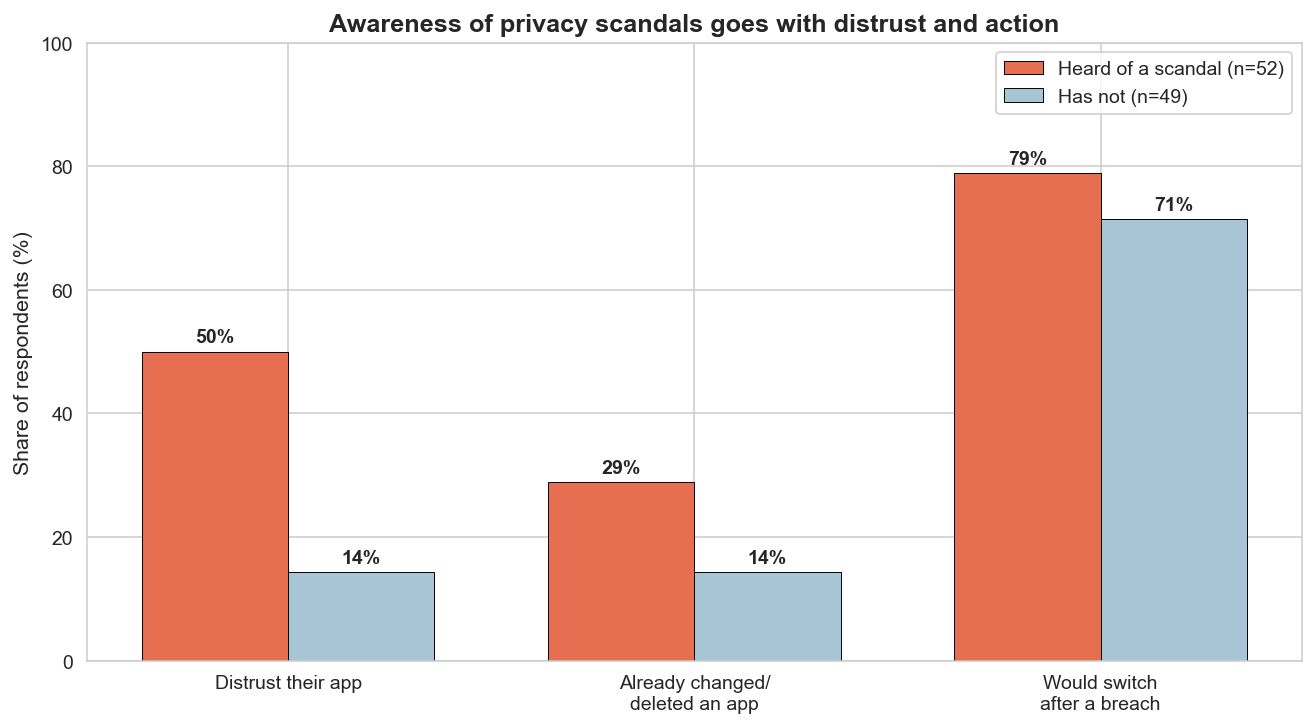

In [22]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd, os
d = pd.read_csv(os.path.join(ADV, 'survey_clean.csv'))
d['acted']=d['changed'].eq('Yes')
d['distrust']=d['trust'].isin(['Mostly distrust it','Do not trust it at all'])
d['knew_scandal']=d['scandal'].isin(['Yes, I know the details',"I've heard something but don't know much"])
d['would_exit']=d['switch_breach'].isin(['Yes, definitely','Probably yes'])
groups=[('scandal', d[d.knew_scandal]), ('not', d[~d.knew_scandal])]
metrics=['distrust','acted','would_exit']
mlab=['Distrust their app','Already changed/\ndeleted an app','Would switch\nafter a breach']
vals=np.array([[g[m].mean()*100 for m in metrics] for _,g in groups])
x=np.arange(len(metrics)); w=0.36
fig,ax=plt.subplots(figsize=(9.5,5.3))
b1=ax.bar(x-w/2,vals[0],w,label=f'Heard of a scandal (n={len(groups[0][1])})',color='#e76f51',edgecolor='black',lw=0.5)
b2=ax.bar(x+w/2,vals[1],w,label=f'Has not (n={len(groups[1][1])})',color='#a8c5d6',edgecolor='black',lw=0.5)
for b in (b1,b2):
    for r in b: ax.text(r.get_x()+r.get_width()/2,r.get_height()+1.5,f'{r.get_height():.0f}%',ha='center',fontweight='bold',fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(mlab,fontsize=10); ax.set_ylim(0,100)
ax.set_ylabel('Share of respondents (%)',fontsize=11)
ax.set_title('Awareness of privacy scandals goes with distrust and action',fontsize=13,fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_survey_scandal.png'),dpi=150,bbox_inches='tight'); plt.show()

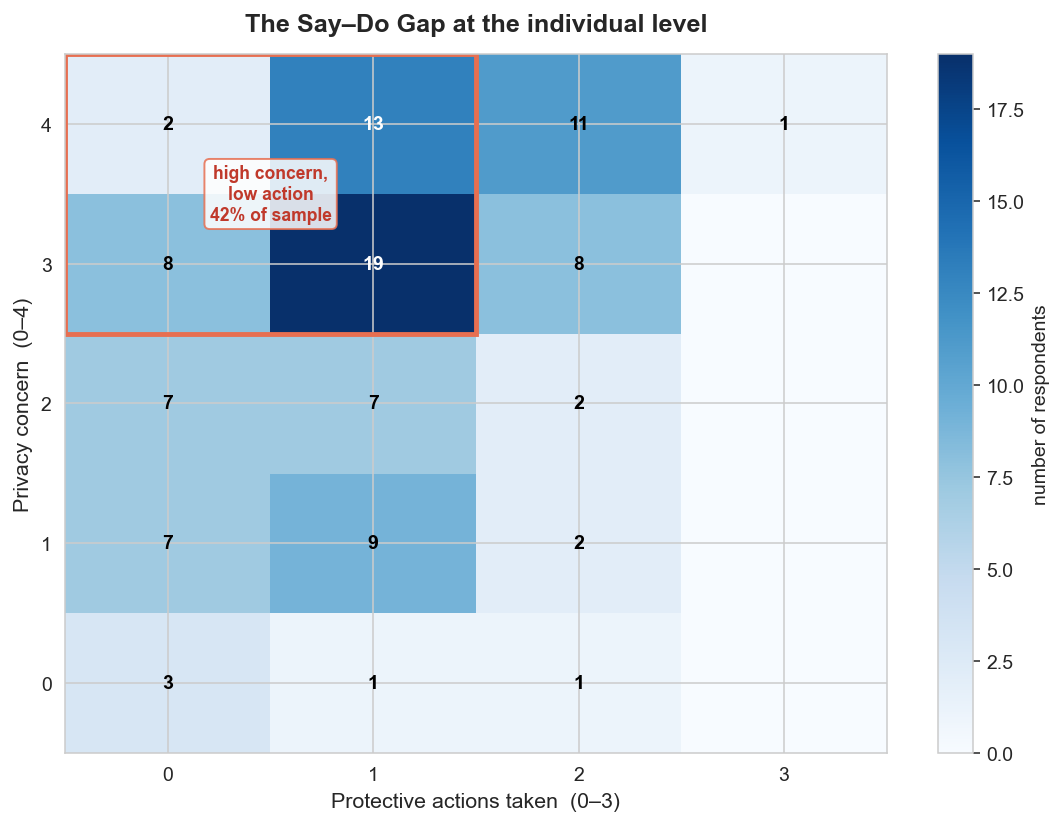

concern mean 2.60/4, action mean 0.99/3, corr 0.35


In [23]:
from matplotlib.patches import Rectangle
d['read_any']=~d['read_policy'].isin(['I accepted it without reading',"I don't remember"])
d['sens_yes']=d['sensitive'].isin(['Yes, very sensitive','Somewhat sensitive'])
d['suspect_unaware']=d['unaware'].isin(['Yes, definitely','Possibly'])
d['knew_3p']=d['know_3p'].isin(['Yes, I was fully aware',"I suspected but wasn't sure"])
concern=d[['sens_yes','distrust','suspect_unaware','knew_3p']].sum(axis=1)
action=(d['read_any'].astype(int)+d['acted'].astype(int)
        +d['sell_action'].isin(['Delete the app immediately','Look for a more privacy-focused alternative']).astype(int))
grid=pd.crosstab(concern,action).reindex(index=range(0,5),columns=range(0,4),fill_value=0)
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(grid.values,cmap='Blues',origin='lower',aspect='auto')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v=grid.values[i,j]
        if v>0: ax.text(j,i,int(v),ha='center',va='center',fontweight='bold',color='white' if v>grid.values.max()*0.6 else 'black')
ax.add_patch(Rectangle((-0.5,2.5),2,2,fill=False,edgecolor='#e76f51',lw=2.5))
ax.text(0.5,3.5,'high concern,\nlow action\n42% of sample',color='#c0392b',ha='center',va='center',
        fontsize=9,fontweight='bold',bbox=dict(boxstyle='round',fc='white',ec='#e76f51',alpha=0.85))
ax.set_xticks(range(4)); ax.set_yticks(range(5))
ax.set_xlabel('Protective actions taken  (0–3)',fontsize=11); ax.set_ylabel('Privacy concern  (0–4)',fontsize=11)
ax.set_title('The Say–Do Gap at the individual level',fontsize=13,fontweight='bold',pad=12)
plt.colorbar(im,ax=ax,label='number of respondents')
plt.tight_layout(); plt.savefig(os.path.join(ADV,'fig_survey_saydo_indiv.png'),dpi=150,bbox_inches='tight'); plt.show()
print('concern mean %.2f/4, action mean %.2f/3, corr %.2f'%(concern.mean(),action.mean(),np.corrcoef(concern,action)[0,1]))